In [1]:
# --- Auto-save plots setup ---
import os

# Keep matplotlib figures open across cells so they can be saved on show()
try:
    from IPython import get_ipython
    ip = get_ipython()
    if ip is not None:
        ip.run_line_magic('config', 'InlineBackend.close_figures=False')
except Exception:
    pass

# Deterministic output directory for this notebook (matches results zip structure)
RUN_DIR = os.path.join("group_conditional_gender")
os.makedirs(RUN_DIR, exist_ok=True)

# Plot saver: saves each matplotlib figure when plt.show() is called.
import matplotlib.pyplot as plt
from utils.plot_saver import PlotSaver, patch_matplotlib_show

PLOT_SAVER = PlotSaver(run_dir=RUN_DIR, subdir='figures', exts=('png',), dpi=300)
patch_matplotlib_show(plt, PLOT_SAVER)

print('✅ Auto-save enabled. RUN_DIR =', os.path.abspath(RUN_DIR))


✅ Auto-save enabled. RUN_DIR = outputs/notebook_runs/20260216_162542


In [2]:
import os
import requests
import zipfile
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import random



random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)


In [3]:

###############################################################################
# Download & load raw data
###############################################################################

def download_movielens_100k(dest_path='ml-100k.zip'):
    url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
    if not os.path.exists(dest_path):
        print("Downloading MovieLens 100k dataset...")
        r = requests.get(url, stream=True)
        with open(dest_path, 'wb') as f:
            for chunk in r.iter_content(chunk_size=1024):
                if chunk:
                    f.write(chunk)
        print("Download completed.")
    else:
        print("MovieLens 100k zip already exists. Skipping download.")

def extract_movielens_100k(zip_path='ml-100k.zip', extract_to='.'):
    ml_folder = os.path.join(extract_to, 'ml-100k')
    if not os.path.exists(ml_folder):
        print("Extracting ml-100k.zip...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_to)
        print("Extraction completed.")
    else:
        print("ml-100k folder already exists. Skipping extraction.")

def load_ratings(path='ml-100k/u.data'):
    df = pd.read_csv(
        path,
        sep='\t',
        names=["user_id", "item_id", "rating", "timestamp"],
        engine='python'
    )
    return df

def load_users(path='ml-100k/u.user'):
    user_cols = ["user_id", "age", "gender", "occupation", "zip_code"]
    df_users = pd.read_csv(
        path,
        sep='|',
        names=user_cols,
        engine='python'
    )
    return df_users

def load_items(path='ml-100k/u.item'):
    item_cols = [
        "item_id",
        "movie_title",
        "release_date",
        "video_release_date",
        "imdb_url",
        "unknown",
        "Action",
        "Adventure",
        "Animation",
        "Children's",
        "Comedy",
        "Crime",
        "Documentary",
        "Drama",
        "Fantasy",
        "Film-Noir",
        "Horror",
        "Musical",
        "Mystery",
        "Romance",
        "Sci-Fi",
        "Thriller",
        "War",
        "Western"
    ]
    df_items = pd.read_csv(
        path,
        sep='|',
        names=item_cols,
        encoding='latin-1',
        engine='python'
    )
    return df_items

def split_data(df, train_frac=0.8, calib_frac=0.1, test_frac=0.1, seed=42):
    df_shuffled = df.sample(frac=1, random_state=seed).reset_index(drop=True)
    n = len(df_shuffled)
    train_end = int(train_frac * n)
    calib_end = int((train_frac + calib_frac) * n)

    train_df = df_shuffled.iloc[:train_end]
    calib_df = df_shuffled.iloc[train_end:calib_end]
    test_df = df_shuffled.iloc[calib_end:]
    return train_df, calib_df, test_df

###############################################################################
# Preprocessing (including user/item ID reindexing & classification target)
###############################################################################

def preprocess_data_classification(merged_df):
    """
    1. Convert rating in [1..5] => class index [0..4].
    2. Re-index user_id and item_id => [0..num_users-1], [0..num_items-1].
    3. Encode gender => {M:0, F:1}, encode occupation & zip_code.
    4. Extract release_year from release_date.
    5. Return a DataFrame with numeric columns and these new IDs.
    """
    df = merged_df.copy()

    # 1) rating => [0..4]
    df['rating_class'] = df['rating'] - 1  # rating 1 => class 0, rating 5 => class 4

    # 2) re-index user_id
    unique_users = df['user_id'].unique()
    user2idx = {u: i for i, u in enumerate(unique_users)}
    df['user_id_idx'] = df['user_id'].map(user2idx)

    # re-index item_id
    unique_items = df['item_id'].unique()
    item2idx = {i: j for j, i in enumerate(unique_items)}
    df['item_id_idx'] = df['item_id'].map(item2idx)

    # 3) encode gender => {M:0, F:1}
    df['gender'] = df['gender'].map({'M': 0, 'F': 1}).fillna(0).astype(int)

    # encode occupation
    occ_unique = df['occupation'].unique().tolist()
    occ_to_idx = {o: i for i, o in enumerate(occ_unique)}
    df['occupation'] = df['occupation'].map(occ_to_idx).fillna(0).astype(int)

    # encode zip_code similarly
    zip_unique = df['zip_code'].unique().tolist()
    zip_to_idx = {z: i for i, z in enumerate(zip_unique)}
    df['zip_code'] = df['zip_code'].map(zip_to_idx).fillna(0).astype(int)

    # 4) parse release_year
    def extract_year(date_str):
        if pd.isna(date_str):
            return 0
        parts = date_str.split('-')
        if len(parts) == 3:
            try:
                return int(parts[2])  # e.g. "01-Jan-1994" => 1994
            except:
                return 0
        else:
            return 0
    df['release_year'] = df['release_date'].apply(extract_year)

    # drop unused columns
    df.drop(columns=['movie_title', 'release_date', 'video_release_date',
                     'imdb_url'], inplace=True)

    return df, user2idx, item2idx

###############################################################################
# PyTorch Dataset for classification
###############################################################################

class MovieLensClassifDataset(Dataset):
    def __init__(self, df):
        super().__init__()

        # We'll store user_id_idx, item_id_idx as separate columns for embeddings
        self.user_ids = torch.tensor(df['user_id_idx'].values, dtype=torch.long)
        self.item_ids = torch.tensor(df['item_id_idx'].values, dtype=torch.long)

        # rating_class is [0..4]
        self.y = torch.tensor(df['rating_class'].values, dtype=torch.long)

        # Prepare side features: age, gender, occupation, zip_code, timestamp, release_year, plus genre flags, etc.
        # We'll decide which columns to treat as side features:
        side_cols = [
            'age', 'gender', 'occupation', 'zip_code', 'timestamp', 'release_year',
            'unknown', 'Action', 'Adventure', 'Animation', "Children's", 'Comedy',
            'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror',
            'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western'
        ]

        # Make sure those columns exist in df
        for col in side_cols:
            if col not in df.columns:
                df[col] = 0  # or handle differently if missing

        self.side_info = torch.tensor(df[side_cols].values, dtype=torch.float32)
        self.side_cols = side_cols

    def __len__(self):
        return len(self.user_ids)

    def __getitem__(self, idx):
        return (self.user_ids[idx],
                self.item_ids[idx],
                self.side_info[idx]), self.y[idx]

###############################################################################
# Model: Embedding for user/item + MLP on side info => combine => final 5 logits
###############################################################################

class DeepRecommenderClassifier(nn.Module):
    def __init__(self,
                 num_users,
                 num_items,
                 user_emb_dim=20,
                 item_emb_dim=20,
                 side_in_dim=26,  # depends on how many side columns
                 side_hidden=32,
                 final_hidden=32,
                 num_classes=5,
                 dropout_rate=0.3):
        """
        num_users, num_items: for embeddings
        user_emb_dim, item_emb_dim: embedding sizes
        side_in_dim: dimension of side_info
        side_hidden: hidden dim for side MLP
        final_hidden: hidden dim after combining
        num_classes: we have 5 rating classes (0..4)
        dropout_rate: dropout probability
        """
        super().__init__()

        # Embeddings
        self.user_emb = nn.Embedding(num_users, user_emb_dim)
        self.item_emb = nn.Embedding(num_items, item_emb_dim)

        # MLP for side info with BatchNorm and Dropout
        self.side_mlp = nn.Sequential(
            nn.Linear(side_in_dim, side_hidden),
            nn.BatchNorm1d(side_hidden),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(side_hidden, side_hidden),
            nn.BatchNorm1d(side_hidden),
            nn.ReLU(),
            nn.Dropout(dropout_rate)
        )

        # Final combination
        comb_in_dim = user_emb_dim + item_emb_dim + side_hidden

        self.final_mlp = nn.Sequential(
            nn.Linear(comb_in_dim, final_hidden),
            nn.BatchNorm1d(final_hidden),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(final_hidden, num_classes)
        )

    def forward(self, user_ids, item_ids, side_info):
        # Look up embeddings
        ue = self.user_emb(user_ids)   # (batch, user_emb_dim)
        ie = self.item_emb(item_ids)   # (batch, item_emb_dim)

        # MLP on side info
        se = self.side_mlp(side_info)  # (batch, side_hidden)

        # Combine
        x = torch.cat([ue, ie, se], dim=1)  # (batch, user_dim + item_dim + side_hidden)
        logits = self.final_mlp(x)          # (batch, 5)
        return logits

###############################################################################
# Training + accuracy
###############################################################################

def train_one_epoch_classif(model, loader, optimizer, device='cpu'):
    model.train()
    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    total_samples = 0

    for (user_ids, item_ids, side_info), y_class in loader:
        user_ids = user_ids.to(device)
        item_ids = item_ids.to(device)
        side_info = side_info.to(device)
        y_class = y_class.to(device)

        optimizer.zero_grad()
        logits = model(user_ids, item_ids, side_info)
        loss = criterion(logits, y_class)
        loss.backward()
        optimizer.step()

        batch_size = y_class.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    avg_loss = total_loss / total_samples
    return avg_loss

def evaluate_classif(model, loader, device='cpu'):
    """
    Returns average cross-entropy and accuracy (exact match).
    """
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')  # sum to do total
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for (user_ids, item_ids, side_info), y_class in loader:
            user_ids = user_ids.to(device)
            item_ids = item_ids.to(device)
            side_info = side_info.to(device)
            y_class = y_class.to(device)

            logits = model(user_ids, item_ids, side_info)
            loss = criterion(logits, y_class)

            # Accuracy
            preds = torch.argmax(logits, dim=1)
            total_correct += (preds == y_class).sum().item()

            total_samples += y_class.size(0)
            total_loss += loss.item()

    avg_loss = total_loss / total_samples
    accuracy = 100.0 * total_correct / total_samples
    return avg_loss, accuracy


In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Using device:", device)

# 1. Download & extract
download_movielens_100k("ml-100k.zip")
extract_movielens_100k("ml-100k.zip", ".")

# 2. Load data
ratings_df = load_ratings("ml-100k/u.data")
users_df   = load_users("ml-100k/u.user")
items_df   = load_items("ml-100k/u.item")

# 3. Merge
merged_df = pd.merge(ratings_df, users_df, on="user_id", how="left")
merged_df = pd.merge(merged_df, items_df, on="item_id", how="left")

# 4. Preprocess for classification
df_classif, user2idx, item2idx = preprocess_data_classification(merged_df)

# 5. Split
train_df, calib_df, test_df = split_data(df_classif, 0.8, 0.1, 0.1, seed=42)
print(f"Train: {train_df.shape}, Calib: {calib_df.shape}, Test: {test_df.shape}")

# 6. Datasets & Loaders
train_data = MovieLensClassifDataset(train_df)
calib_data = MovieLensClassifDataset(calib_df)
test_data  = MovieLensClassifDataset(test_df)

train_loader = DataLoader(train_data, batch_size=256, shuffle=True)
calib_loader = DataLoader(calib_data, batch_size=256, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=256, shuffle=False)

# 7. Model
num_users = len(user2idx)
num_items = len(item2idx)
# side_in_dim = number of features in side_info (determined by dataset).
# Let's see:
side_in_dim = train_data.side_info.shape[1]
print("Side info dimension:", side_in_dim)

model = DeepRecommenderClassifier(
    num_users=num_users,
    num_items=num_items,
    user_emb_dim=32,
    item_emb_dim=32,
    side_in_dim=side_in_dim,
    side_hidden=64,
    final_hidden=64,
    num_classes=5
).to(device)

optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 8. Training loop
epochs = 20
for epoch in range(1, epochs+1):
    train_loss = train_one_epoch_classif(model, train_loader, optimizer, device)
    val_loss, val_acc = evaluate_classif(model, calib_loader, device)
    print(f"Epoch {epoch}/{epochs}: Train Loss={train_loss:.4f}, "
          f"Val Loss={val_loss:.4f}, Val Acc={val_acc:.2f}%")

# 9. Final test evaluation
test_loss, test_acc = evaluate_classif(model, test_loader, device)
print(f"\nFinal Test Loss={test_loss:.4f}, Test Accuracy={test_acc:.2f}%")


Using device: cuda
MovieLens 100k zip already exists. Skipping download.
ml-100k folder already exists. Skipping extraction.
Train: (80000, 31), Calib: (10000, 31), Test: (10000, 31)
Side info dimension: 25
Epoch 1/20: Train Loss=1.4755, Val Loss=1.4853, Val Acc=35.19%
Epoch 2/20: Train Loss=1.4209, Val Loss=1.4247, Val Acc=34.54%
Epoch 3/20: Train Loss=1.3792, Val Loss=1.3534, Val Acc=39.88%
Epoch 4/20: Train Loss=1.3399, Val Loss=1.3286, Val Acc=40.65%
Epoch 5/20: Train Loss=1.3114, Val Loss=1.2998, Val Acc=41.82%
Epoch 6/20: Train Loss=1.2887, Val Loss=1.3034, Val Acc=41.74%
Epoch 7/20: Train Loss=1.2719, Val Loss=1.2876, Val Acc=43.09%
Epoch 8/20: Train Loss=1.2604, Val Loss=1.2849, Val Acc=43.19%
Epoch 9/20: Train Loss=1.2496, Val Loss=1.2623, Val Acc=43.93%
Epoch 10/20: Train Loss=1.2406, Val Loss=1.2594, Val Acc=44.37%
Epoch 11/20: Train Loss=1.2333, Val Loss=1.2561, Val Acc=44.40%
Epoch 12/20: Train Loss=1.2280, Val Loss=1.2552, Val Acc=44.41%
Epoch 13/20: Train Loss=1.2234, Va

**Implementation of the best response baseline.:**

In [5]:
import torch
import numpy as np

def evaluate_baseline_best_response(model, test_loader, alpha, device='cpu'):
    """
    Baseline: for each sample, pick the action (recommend/not recommend) that
    maximizes the *expected utility* given the model's predicted probabilities.

    Utility function (as in original code):
      - If a=0 (not recommend), u=0.
      - If a=1 (recommend), u = (rating in [1..5]) - 3.

    Reports:
      - Average utility
      - Percentage recommended by true rating
      - Utility histogram (empirical PDF)
      - alpha-quantile of realized utilities
    """
    model.eval()
    model.to(device)

    # Keep track of total utility and sample count
    total_utility = 0.0
    total_samples = 0
    utility_values = []

    # rating_counts[r], recommend_counts[r] for r in [1..5]
    rating_counts = {r: 0 for r in [1, 2, 3, 4, 5]}
    recommend_counts = {r: 0 for r in [1, 2, 3, 4, 5]}

    # Utility histogram for possible realized utilities in {-2, -1, 0, 1, 2}
    # (since u=0 if not recommend, or u=(r-3) if recommend)
    utility_histogram = {u: 0 for u in [-2, -1, 0, 1, 2]}

    with torch.no_grad():
        for batch in test_loader:
            (user_ids, item_ids, side_info), y_true_class = batch
            user_ids   = user_ids.to(device)
            item_ids   = item_ids.to(device)
            side_info  = side_info.to(device)
            y_true_class = y_true_class.to(device)  # rating in [0..4], so "true rating" = y_true_class+1 in [1..5]

            # Forward pass -> logits -> convert to probabilities
            logits = model(user_ids, item_ids, side_info)  # shape (batch_size, 5)
            probs  = torch.softmax(logits, dim=1)          # shape (batch_size, 5)

            batch_size = y_true_class.shape[0]

            for i in range(batch_size):
                # True rating is in [1..5]
                r_true = int(y_true_class[i].item()) + 1
                rating_counts[r_true] += 1
                total_samples += 1

                # Probability vector for the 5 possible ratings
                p_vec = probs[i]  # shape (5,)
                # We'll move it to CPU numpy for easier handling, if needed
                p_np = p_vec.detach().cpu().numpy()

                # For each action a in {0,1}, compute E[u(a)] = sum_{r=1..5} p[r-1]*u(a, r)
                # where u(0,r)=0 and u(1,r)=r-3
                # Let's define a small function for this local case:
                def exp_utility(a):
                    e_val = 0.0
                    for rating_idx in range(5):  # rating_idx=0..4 => r=rating_idx+1
                        r = rating_idx + 1
                        if a == 1:
                            # recommend => utility = r - 3
                            e_val += p_np[rating_idx] * (r - 3)
                        else:
                            # a=0 => no recommend => utility=0
                            e_val += p_np[rating_idx] * 0.0
                    return e_val

                # Decide best action
                exp_u_0 = exp_utility(a=0)
                exp_u_1 = exp_utility(a=1)
                if exp_u_1 > exp_u_0:
                    final_action = 1  # recommend
                else:
                    final_action = 0  # not recommend

                # Realized utility with the true rating r_true
                if final_action == 1:
                    # recommend => utility = r_true - 3
                    u_val = r_true - 3
                    recommend_counts[r_true] += 1
                else:
                    # not recommend => utility = 0
                    u_val = 0

                total_utility += u_val
                utility_values.append(u_val)

                # Update utility histogram if it's in [-2, -1, 0, 1, 2]
                if u_val in utility_histogram:
                    utility_histogram[u_val] += 1

    # Averages
    avg_utility = total_utility / total_samples if total_samples > 0 else 0.0

    # Percentage recommended by true rating
    recommend_percents = {}
    for r in [1, 2, 3, 4, 5]:
        if rating_counts[r] > 0:
            perc = 100.0 * recommend_counts[r] / rating_counts[r]
        else:
            perc = 0.0
        recommend_percents[r] = perc

    # Convert histogram to PDF
    total_util_count = sum(utility_histogram.values())
    utility_pdf = {}
    for u_val, count in utility_histogram.items():
        if total_util_count > 0:
            utility_pdf[u_val] = count / total_util_count
        else:
            utility_pdf[u_val] = 0.0

    # alpha-Quantile of realized utilities
    sorted_utils = sorted(utility_values)
    alpha_quantile = float(np.quantile(sorted_utils, alpha)) if len(sorted_utils) > 0 else 0.0

    print("=== Baseline: Best Response (Expected Utility) ===")
    print(f"Average Utility = {avg_utility:.4f}")
    for r in [1, 2, 3, 4, 5]:
        print(f"  True rating {r}: recommended {recommend_percents[r]:.2f}% of the time")

    print("Utility Histogram (Empirical PDF):")
    for u_val in sorted(utility_pdf.keys()):
        print(f"  Utility {u_val}: {utility_pdf[u_val]:.4f}")

    print(f"Alpha-Quantile ({alpha*100:.1f}%): {alpha_quantile:.4f}")

    return avg_utility, recommend_percents, utility_pdf, alpha_quantile


An example.

In [6]:
avg_utility, recommend_stats, utility_pdf, _ = evaluate_baseline_best_response(model, test_loader, 0.1, device=device)
print(utility_pdf)

=== Baseline: Best Response (Expected Utility) ===
Average Utility = 0.5952
  True rating 1: recommended 45.64% of the time
  True rating 2: recommended 66.14% of the time
  True rating 3: recommended 82.42% of the time
  True rating 4: recommended 95.08% of the time
  True rating 5: recommended 97.93% of the time
Utility Histogram (Empirical PDF):
  Utility -2: 0.0293
  Utility -1: 0.0789
  Utility 0: 0.3621
  Utility 1: 0.3267
  Utility 2: 0.2030
Alpha-Quantile (10.0%): -1.0000
{-2: 0.0293, -1: 0.0789, 0: 0.3621, 1: 0.3267, 2: 0.203}


**Implementation of score-1**

In [7]:
import torch
import numpy as np

###############################################################################
# 1) Compute the conformal threshold T on the calibration set
###############################################################################

def compute_conformal_threshold(model, calib_loader, alpha=0.2, device='cpu'):
    """
    - model: classification model with logits of shape (batch_size, 5)
    - calib_loader: DataLoader for the calibration set
    - alpha=0.2 => coverage ~80%
    Returns: threshold T
    """
    model.eval()
    model.to(device)

    nonconformity_scores = []

    with torch.no_grad():
        for batch in calib_loader:
            # batch => ([user_ids, item_ids, side_info], y_class)
            #   y_class in {0..4}
            (user_ids, item_ids, side_info), y_class = batch

            user_ids  = user_ids.to(device)
            item_ids  = item_ids.to(device)
            side_info = side_info.to(device)
            y_class   = y_class.to(device)

            # Forward => logits => softmax => probabilities
            logits = model(user_ids, item_ids, side_info)  # (batch_size, 5)
            probs = torch.softmax(logits, dim=1)           # shape (batch_size,5)

            # For each i in batch, nonconformity = 1 - p_{y_i}(x_i)
            # y_class[i] is an integer 0..4
            for i in range(len(y_class)):
                true_c = y_class[i].item()        # 0..4
                p_true = probs[i, true_c].item()  # predicted probability for the correct class
                score = 1.0 - p_true
                nonconformity_scores.append(score)

    # Convert to numpy
    nonconformity_scores = np.array(nonconformity_scores)

    # Compute the (1-alpha) quantile => T
    # e.g. np.quantile(nonconformity_scores, 1-alpha)
    # We'll use method='higher' to be conservative, or you can choose method='linear'.
    T = float(np.quantile(nonconformity_scores, 1 - alpha, method='higher'))

    return T

###############################################################################
# 2) Evaluate the risk-averse policy on test set
###############################################################################

import torch
import numpy as np
from collections import defaultdict, Counter

def evaluate_conformal_policy(
    model,
    test_loader,
    T,
    u,
    alpha,
    device='cpu'
):
    """
    - model: classification model
    - test_loader: DataLoader for test set
    - T: threshold from conformal calibration
    - u: utility function: u(action, c) -> real
    - alpha: quantile value for utility histogram
    - device: 'cpu' or 'cuda'

    Policy (unchanged):
      1) For each sample, form S_indices = { c': p[c'] >= 1 - T }.
      2) If {0..2} intersect S_indices, utility = u(0, c) (not recommended),
         else utility = u(1, c) (recommended).

    Reports:
      - coverage: fraction of times c in S_indices
      - avg_utility
      - recommend_percents
      - utility_histogram & PDF
      - alpha-quantile
      - avg_maxmin (set to 0.0 here, for consistency with other baselines)
    """

    model.eval()
    model.to(device)

    total_utility = 0.0
    total_maxmin = 0.0
    total_samples = 0
    utility_values = []

    # Coverage counter
    coverage_count = 0

    # Track counts by true rating [1..5]
    rating_counts = {r: 0 for r in [1, 2, 3, 4, 5]}
    recommend_counts = {r: 0 for r in [1, 2, 3, 4, 5]}

    # We'll keep a histogram of possible utilities.
    # If you expect them only in [-2, -1, 0, 1, 2], you can keep that fixed.
    # Otherwise, let's use a Counter to track any realized utility.
    from collections import defaultdict
    utility_histogram = defaultdict(int)

    with torch.no_grad():
        for batch in test_loader:
            (user_ids, item_ids, side_info), y_class = batch
            user_ids  = user_ids.to(device)
            item_ids  = item_ids.to(device)
            side_info = side_info.to(device)
            y_class   = y_class.to(device)  # in [0..4]

            logits = model(user_ids, item_ids, side_info)
            probs = torch.softmax(logits, dim=1)  # shape: (batch_size, 5)
            batch_size = y_class.shape[0]

            for i in range(batch_size):
                c = int(y_class[i].item())  # true class in [0..4]
                r = c + 1  # true rating in [1..5]
                rating_counts[r] += 1
                total_samples += 1

                # Form S_indices
                p = probs[i]  # shape (5,)
                cutoff = 1.0 - T
                S_indices = (p >= cutoff).nonzero(as_tuple=True)[0].tolist()  # list of class indices

                # Coverage check
                if c in S_indices:
                    coverage_count += 1

                # Realized utility
                if any(x in [0,1,2] for x in S_indices):
                    # Not recommend
                    utility = u(0, c)
                    total_maxmin+=0
                elif 3 in S_indices:
                    # Recommend
                    utility = u(1, c)
                    recommend_counts[r] += 1
                    total_maxmin+=1
                else:
                    utility = u(1, c)
                    recommend_counts[r] += 1
                    total_maxmin+=2

                total_utility += utility
                utility_values.append(utility)
                utility_histogram[utility] += 1

    # 1) Coverage
    coverage = coverage_count / total_samples if total_samples > 0 else 0.0

    # 2) Average utility
    avg_utility = total_utility / total_samples if total_samples > 0 else 0.0
    avg_maxmin = total_maxmin / total_samples if total_samples > 0 else 0.0

    # 3) Recommendation percentages
    recommend_percents = {}
    for r in [1, 2, 3, 4, 5]:
        if rating_counts[r] > 0:
            recommend_percents[r] = 100.0 * recommend_counts[r] / rating_counts[r]
        else:
            recommend_percents[r] = 0.0

    # 4) Convert histogram to empirical PDF
    total_count = sum(utility_histogram.values())
    utility_pdf = {}
    for val, cnt in utility_histogram.items():
        if total_count > 0:
            utility_pdf[val] = cnt / total_count
        else:
            utility_pdf[val] = 0.0

    # 6) Print results
    print("=== Conformal Policy (risk-averse) ===")
    print(f"Threshold T = {T:.4f}, alpha={alpha}")
    print(f"Coverage: {coverage:.3f}")
    print(f"Average Utility: {avg_utility:.4f}\n")
    print("Recommend % by TRUE rating:")
    for r in [1, 2, 3, 4, 5]:
        print(f"  Rating={r}: recommended {recommend_percents[r]:.2f}%")

    print("\nUtility Histogram (Empirical Distribution):")
    for val in sorted(utility_pdf.keys()):
        print(f"  Utility {val}: {utility_pdf[val]:.4f}")
    # 7) Return a dictionary of results
    results_dict = {
        "coverage": coverage,
        "avg_utility": avg_utility,
        "recommend_percents": recommend_percents,
        "utility_histogram": dict(utility_histogram),
        "utility_pdf": utility_pdf,
        "avg_maxmin_value": avg_maxmin  # no max-min logic here, but included for consistency
    }

    return results_dict

###############################################################################
# USAGE EXAMPLE
###############################################################################

# You can run something like:
def example_utility_fn(a, y):
    # a=0 => "not recommend", a=1 => "recommend"
    if a == 0:
        return 0.0
    else:
        # a=1 => let's define u = (y-2)
        return float(y - 2)

alpha = 0.2
T = compute_conformal_threshold(model, calib_loader, alpha=alpha, device=device)
results= evaluate_conformal_policy(model, test_loader, T, example_utility_fn, alpha, device=device)


=== Conformal Policy (risk-averse) ===
Threshold T = 0.8093, alpha=0.2
Coverage: 0.792
Average Utility: 0.3759

Recommend % by TRUE rating:
  Rating=1: recommended 9.50%
  Rating=2: recommended 11.15%
  Rating=3: recommended 18.11%
  Rating=4: recommended 38.13%
  Rating=5: recommended 65.22%

Utility Histogram (Empirical Distribution):
  Utility -2.0: 0.0061
  Utility -1.0: 0.0133
  Utility 0.0: 0.7144
  Utility 1.0: 0.1310
  Utility 2.0: 0.1352


**Implementation of Score-2**

In [8]:
import torch
import numpy as np

def compute_conformal_threshold_newscore(model, calib_loader, alpha=0.2, device='cpu'):
    """
    Computes threshold T for the new non-conformity score:
      score(x, y) = sum_{y' != y : p(y') > p(y)} p(y')

    Steps:
      1) For each sample in calib_loader, compute probabilities p(y').
      2) Let the true class = y_class in [0..4].
         The score = sum of p(y') for all y' s.t. p(y') > p(y_class).
      3) Collect all scores, pick the (1-alpha)-quantile => T.
    """
    model.eval()
    model.to(device)

    nonconformity_scores = []

    with torch.no_grad():
        for batch in calib_loader:
            (user_ids, item_ids, side_info), y_class = batch
            user_ids   = user_ids.to(device)
            item_ids   = item_ids.to(device)
            side_info  = side_info.to(device)
            y_class    = y_class.to(device)  # in [0..4]

            logits = model(user_ids, item_ids, side_info)
            probs  = torch.softmax(logits, dim=1)  # shape (batch_size, 5)

            batch_size = y_class.shape[0]
            for i in range(batch_size):
                c = int(y_class[i].item())    # the true class
                p_true = probs[i, c].item()   # p(y_class)

                # Non-conformity score: sum of p[y'] for y' != c where p[y'] > p[c]
                score = 0.0
                for y_prime in range(5):
                    if y_prime != c:
                        p_yp = probs[i, y_prime].item()
                        if p_yp > p_true:
                            score += p_yp
                nonconformity_scores.append(score)

    # Convert to numpy and pick the (1-alpha) quantile
    nonconformity_scores = np.array(nonconformity_scores)
    T = float(np.quantile(nonconformity_scores, 1 - alpha, method='higher'))

    return T

import torch
import numpy as np
from collections import Counter

def evaluate_conformal_policy_newscore(
    model,
    test_loader,
    T,
    u,
    device='cpu'
):
    """
    - model: classification model
    - test_loader: DataLoader returning ([u, i, side_info], y_class)
    - T: threshold from the new non-conformity definition
    - u: utility function with signature u(action, c)
    - device: 'cpu' or 'cuda'

    Policy (unchanged):
      1) For each x, compute S(x) = { c' : score(x, c') <= T },
         where score(x, c') = sum_{c'' != c'} p_c''(x) for c'' s.t. p_c''(x) > p_c'(x).
      2) If {0 or 1} or 2 in S(x) => do NOT recommend
         Else if 3 in S(x) => recommend => total_maxmin += 1
         Else => recommend => total_maxmin += 2
         Realized utility is set accordingly.

    We now also:
      - Check coverage: (true_label in S(x))
      - Track a histogram of realized utilities
      - Return coverage, avg_utility, avg_maxmin, recommend% by rating, plus utility histogram
    """
    model.eval()
    model.to(device)

    total_utility = 0.0
    total_maxmin = 0.0
    total_samples = 0

    # Coverage count
    coverage_count = 0

    # For realized utilities, create a histogram. We don't know the possible range,
    # but let's store them in a Counter, which can handle any integer or float.
    from collections import defaultdict
    utility_histogram = defaultdict(int)
    utility_values = []

    # rating_counts[r], recommend_counts[r] for r in [1..5]
    rating_counts = {r: 0 for r in range(1, 6)}
    recommend_counts = {r: 0 for r in range(1, 6)}

    with torch.no_grad():
        for batch in test_loader:
            (user_ids, item_ids, side_info), y_class = batch
            user_ids = user_ids.to(device)
            item_ids = item_ids.to(device)
            side_info = side_info.to(device)
            y_class   = y_class.to(device)  # in [0..4]

            # 1) Compute probabilities
            logits = model(user_ids, item_ids, side_info)
            probs  = torch.softmax(logits, dim=1)  # (batch_size, 5)

            batch_size = y_class.shape[0]

            for i in range(batch_size):
                c = int(y_class[i].item())  # true class in [0..4]
                r = c + 1                   # true rating in [1..5]
                rating_counts[r] += 1
                total_samples += 1

                # 2) Build S(x)
                p_vec = probs[i]  # shape (5,)
                S_indices = []
                for cprime in range(5):
                    p_cprime = p_vec[cprime].item()
                    score_cp = 0.0
                    for c2 in range(5):
                        if c2 != cprime:
                            p_c2 = p_vec[c2].item()
                            if p_c2 > p_cprime:
                                score_cp += p_c2
                    if score_cp <= T:
                        S_indices.append(cprime)

                # 3) Coverage check
                if c in S_indices:
                    coverage_count += 1

                # 4) Decide recommended / not recommended
                #    and compute realized utility + maxmin
                if (0 in S_indices) or (1 in S_indices) or (2 in S_indices):
                    # do NOT recommend
                    utility = u(0, c)
                    total_maxmin += 0
                elif 3 in S_indices:
                    # recommend => utility = (c+1) - 3 = c - 2
                    utility = u(1, c)
                    total_maxmin += 1
                    recommend_counts[r] += 1
                else:
                    utility = u(1, c)
                    total_maxmin += 2
                    recommend_counts[r] += 1

                total_utility += utility
                utility_values.append(utility)
                utility_histogram[utility] += 1

    # 5) Summaries
    coverage = coverage_count / total_samples if total_samples > 0 else 0.0
    avg_utility = total_utility / total_samples if total_samples > 0 else 0.0
    avg_maxmin = total_maxmin / total_samples if total_samples > 0 else 0.0

    recommend_percents = {}
    for r in range(1, 6):
        if rating_counts[r] > 0:
            recommend_percents[r] = 100.0 * recommend_counts[r] / rating_counts[r]
        else:
            recommend_percents[r] = 0.0

    # Convert histogram to PDF
    total_hist_count = sum(utility_histogram.values())
    utility_pdf = {}
    for val, cnt in utility_histogram.items():
        if total_hist_count > 0:
            utility_pdf[val] = cnt / total_hist_count
        else:
            utility_pdf[val] = 0.0

    # Print summary
    print("=== Conformal Policy (newscore) ===")
    print(f"Threshold T = {T:.4f}")
    print(f"Coverage = {coverage:.3f}")
    print(f"Average Utility = {avg_utility:.4f}")
    print(f"Average Max-Min Value = {avg_maxmin:.4f}\n")

    print("Recommend % by TRUE rating:")
    for r in [1, 2, 3, 4, 5]:
        print(f"  Rating={r}: recommended {recommend_percents[r]:.2f}%")

    print("\nUtility Histogram (Empirical Distribution):")
    for val in sorted(utility_pdf.keys()):
        print(f"  Utility {val}: {utility_pdf[val]:.4f}")

    # Return dictionary
    results_dict = {
        "coverage": coverage,
        "avg_utility": avg_utility,
        "avg_maxmin_value": avg_maxmin,
        "recommend_percents": recommend_percents,
        "utility_histogram": dict(utility_histogram),
        "utility_pdf": utility_pdf
    }
    return results_dict


An example.

In [9]:
def example_utility_fn(a, y):
    # a=0 => "not recommend", a=1 => "recommend"
    if a == 0:
        return 0.0
    else:
        # a=1 => let's define u = (y-2)
        return float(y - 2)



alpha = 0.2
T_new = compute_conformal_threshold_newscore(model, calib_loader, alpha=alpha, device=device)

# 2) Evaluate on test with the new policy
results = evaluate_conformal_policy_newscore(
    model,
    test_loader,
    T_new,
    example_utility_fn,
    device=device
)

=== Conformal Policy (newscore) ===
Threshold T = 0.7286
Coverage = 0.793
Average Utility = 0.4044
Average Max-Min Value = 0.3910

Recommend % by TRUE rating:
  Rating=1: recommended 8.57%
  Rating=2: recommended 12.15%
  Rating=3: recommended 20.90%
  Rating=4: recommended 43.28%
  Rating=5: recommended 67.82%

Utility Histogram (Empirical Distribution):
  Utility -2.0: 0.0055
  Utility -1.0: 0.0145
  Utility 0.0: 0.6907
  Utility 1.0: 0.1487
  Utility 2.0: 0.1406


**Implementation of the RAC**

In the following cells we will implement all the components that are needed to run RAC. All of these componenets follow the descriptions in the paper. We will also have a running example, which we use to sanity check the componenets throughout this notebook.

In [10]:
import math
import numpy as np

def hbtheta_and_arg(t, actions, f_x, utility_fn):
    """
    Compute (hbtheta_value, best_action) for a single x,t.

    :param t: float in [0,1], feasibility threshold
    :param actions: iterable of possible actions (e.g. [0,1,2,3])
    :param f_x: 1D array-like of probabilities f_x[y], summing to ~1, for y in label space {0..len(f_x)-1}
    :param utility_fn: a function utility_fn(a,y) -> real number
    :return: (best_u, best_a)
      best_u = hbtheta(x,t)
      best_a = argmax action that achieves best_u
    """

    # Convert f_x to a numpy array for vector operations (if not already)
    f_x = np.array(f_x, dtype=float)

    # We'll assume the label space is y in [0..len(f_x)-1].
    Y = np.arange(len(f_x))

    best_u = -math.inf
    best_a = None

    for a in actions:
        # 1) Compute utility for each label y
        #    shape: (len(Y),)
        utilities_for_a = np.array([utility_fn(a, y) for y in Y], dtype=float)

        # 2) Get unique utility values in descending order
        #    e.g. [9, 8, 4, 0, ...]
        unique_util_vals = np.unique(utilities_for_a)
        unique_util_vals = np.sort(unique_util_vals)[::-1]  # descending

        # 3) For each candidate utility value, check if sum_{y : utility>=candidate} f_x[y] >= t
        candidate_u = -math.inf
        for u_candidate in unique_util_vals:
            # Create a boolean mask for labels where utility >= u_candidate
            mask = (utilities_for_a >= u_candidate)
            sum_prob = np.sum(f_x[mask])

            if sum_prob >= t:
                candidate_u = u_candidate
                break  # no need to check smaller utilities

        # 4) Compare across actions
        if candidate_u > best_u:
            best_u = candidate_u
            best_a = a

    return best_u, best_a


In [11]:
import numpy as np
import math

def compute_g_hat(x_probs, beta, actions, utility_fn):
    """
    Compute g_hat(x, beta) = argmax_{s in [0,1]} [ beta*s + h_btheta(x, s) ]
    using only the *relevant* thresholds derived from T(a, u).

    :param x_probs: 1D array-like of probabilities f_x[y], sums to 1
    :param beta: float parameter in [0, 2] (or any real range)
    :param actions: list/iterable of possible actions
    :param utility_fn: function utility_fn(a,y) -> float
    :return: s_star in [0,1] that maximizes beta*s + h_btheta(x, s)

    Explanation:
      - We do NOT search a full grid of 101 points.
      - Instead, for each action a, we gather unique utility values u in descending order,
        compute T(a,u) = sum_{y : utility(a,y) >= u} x_probs[y].
      - h_btheta(x, s) changes only at these T(a,u) thresholds (plus possibly 0 or 1).
      - We then evaluate phi(s) = beta*s + h_btheta(x, s) only at these discrete s-values.
      - The s that yields the highest phi(s) is returned.
    """
    x_probs = np.asarray(x_probs, dtype=float)
    num_labels = len(x_probs)

    # 1) For each action 'a', gather unique utility values + compute T(a,u).
    #    We'll store them in descending order of u so we can quickly parse them.
    #    T(a,u) = sum_{y : utility_fn(a,y) >= u} x_probs[y].
    action_thresholds = {}  # action -> list of (u, T(a,u)) in descending order of u
    all_s_candidates = set([0.0, 1.0])  # we'll include 0 and 1 from the start

    for a in actions:
        # Compute utility for each label y
        utilities_for_a = np.array([utility_fn(a, y) for y in range(num_labels)], dtype=float)

        # Gather unique utilities in descending order
        unique_utils = np.unique(utilities_for_a)
        unique_utils = np.sort(unique_utils)[::-1]  # descending

        # For each u_candidate, compute T(a,u_candidate)
        pairs = []
        for u_candidate in unique_utils:
            mask = (utilities_for_a >= u_candidate)
            t_val = x_probs[mask].sum()
            pairs.append((u_candidate, t_val))
            # This t_val is a potential candidate s
            all_s_candidates.add(float(t_val))  # add to global set of s-candidates

        action_thresholds[a] = pairs  # list of (u, T(a,u)) in descending order of u

    # 2) Now we have a set of possible s in [0,1], including T(a,u) for all a,u plus {0,1}.
    #    We'll evaluate phi(s) = beta*s + h_btheta(x, s) at each candidate.
    #    h_btheta(x, s) = max_{a} [ largest u in pairs for which T(a,u) >= s ]

    s_star = 0.0
    best_score = -math.inf

    # We'll convert to a sorted list (ascending or random). Ascending is typical:
    s_candidates = sorted(all_s_candidates)

    for s in s_candidates:
        # Compute h_btheta(x, s)
        # For each action a, find the largest u s.t. T(a,u) >= s
        best_u_for_s = -math.inf

        for a, pairs in action_thresholds.items():
            # 'pairs' is in descending order of u, so T(a,u) is presumably non-increasing as we go
            # from bigger to smaller u. We'll do a quick linear scan:
            feasible_u = -math.inf
            for (u_candidate, t_val) in pairs:
                if t_val >= s:
                    feasible_u = u_candidate
                    break
            if feasible_u > best_u_for_s:
                best_u_for_s = feasible_u

        # Now we have h_btheta(x, s) = best_u_for_s
        # phi(s) = beta*s + best_u_for_s
        phi_s = beta*s + best_u_for_s

        if phi_s > best_score:
            best_score = phi_s
            s_star = s

    return s_star


In [12]:
# 1) Define a utility function
def example_utility_fn(a, y):
    # a=0 => "not recommend", a=1 => "recommend"
    if a == 0:
        return 0.0
    else:
        # a=1 => let's define u = (y-2)
        return float(y - 2)

# 2) Example distribution over y in [0..4]
f_x = [0.1, 0.1, 0.4, 0.2, 0.2]  # sums to 1.0

# 3) Our set of actions
actions = [0,1]  # or ["not_rec","rec"] if you prefer

# 4) Example t
t = 0.1

# 5) Call the function
best_u, best_a = hbtheta_and_arg(t, actions, f_x, example_utility_fn)
print(f"hbtheta(x={f_x}, t={t}) = {best_u}")
print(f"arg_hbtheta(x={f_x}, t={t}) = {best_a}")


hbtheta(x=[0.1, 0.1, 0.4, 0.2, 0.2], t=0.1) = 2.0
arg_hbtheta(x=[0.1, 0.1, 0.4, 0.2, 0.2], t=0.1) = 1


In [13]:
# Reuse the toy example from before:
def example_utility_fn(a, y):
    # a=0 => utility=0 always, a=1 => utility=(y-2).
    if a == 0:
        return 0.0
    else:
        return float(y - 2)

f_x = [0.1, 0.1, 0.4, 0.2, 0.2]  # sums to 1
actions = [0,1]
beta = 5.6

# We assume 'hbtheta_and_arg' is defined from previous steps
g_star = compute_g_hat(f_x, beta, actions, example_utility_fn)
print(f"g_star for beta={beta} is {g_star:.3f}")


g_star for beta=5.6 is 1.000


In [14]:
from tqdm import tqdm

def get_conformal_set(x_probs, s_value, actions, utility_fn):
    """
    Vectorized approach:
      1) (best_u, best_a) = hbtheta_and_arg(s_value, actions, x_probs, utility_fn)
      2) u_vec[y] = utility_fn(best_a, y)
      3) y in c_star if sum_{y': u_vec[y'] >= u_vec[y]} x_probs[y'] >= s_value
    """
    num_labels = len(x_probs)
    best_u, best_a = hbtheta_and_arg(s_value, actions, x_probs, utility_fn)

    # Vector of shape (num_labels,) for this chosen action
    u_vec = np.array([utility_fn(best_a, y) for y in range(num_labels)], dtype=float)

    c_star = set()

    # We can do an O(num_labels^2) approach with vector masks:
    for y in range(num_labels):
        val_y = u_vec[y]
        mask = (u_vec > val_y)   # vector mask
        sum_prob = x_probs[mask].sum()
        if sum_prob <= s_value:
            c_star.add(y)

    return c_star

def get_conformal_set(x_probs, s_value, actions, utility_fn):
    """
    Vectorized approach:
      1) (best_u, best_a) = hbtheta_and_arg(s_value, actions, x_probs, utility_fn)
      2) u_vec[y] = utility_fn(best_a, y)
      3) y in c_star if sum_{y': u_vec[y'] >= u_vec[y]} x_probs[y'] >= s_value
    """
    num_labels = len(x_probs)
    best_u, best_a = hbtheta_and_arg(s_value, actions, x_probs, utility_fn)

    # Vector of shape (num_labels,) for this chosen action
    u_vec = np.array([utility_fn(best_a, y) for y in range(num_labels)], dtype=float)

    c_star = set()

    # We can do an O(num_labels^2) approach with vector masks:
    for y in range(num_labels):
        val_y = u_vec[y]
        mask = (u_vec > val_y)   # vector mask
        sum_prob = x_probs[mask].sum()
        if sum_prob <= s_value:
            c_star.add(y)

    return c_star


def coverage_for_beta(calib_probs, calib_labels, beta, actions, utility_fn):
    """
    :param calib_probs: list (or array) of length n,
        each element is x_probs[i], i.e. array of shape (num_labels,).
    :param calib_labels: list/array of length n with the true label index for each sample
    :param beta: float
    :param actions: list of possible actions
    :param utility_fn: ...
    :return: coverage in [0,1]
    """
    n = len(calib_probs)
    hits = 0
    for i in range(n):
        x_probs_i = calib_probs[i]
        y_i       = calib_labels[i]

        # compute s_i = g_hat(x, beta)
        s_i = compute_g_hat(x_probs_i, beta, actions, utility_fn)
        # get the set
        c_star_i = get_conformal_set(x_probs_i, s_i, actions, utility_fn)

        # check coverage
        if y_i in c_star_i:
            hits += 1
    return hits / n


def find_threshold_q(calib_probs, calib_labels, alpha, actions, utility_fn, beta_step=0.01, max_beta=2.0):
    """
    Sweep beta from 0..max_beta with step size = beta_step.
    For each beta, compute coverage.
    Return the FIRST beta where coverage >= 1 - alpha.

    :param calib_probs: list/array of shape (n,), each is an array (num_labels,) for x_probs
    :param calib_labels: list/array of shape (n,) with the true label index
    :param alpha: in [0,1]
    :param actions: ...
    :param utility_fn: ...
    :param beta_step: step size for the grid
    :param max_beta: max for the grid
    :return: q (float) or None if not found
    """
    beta_val_now = 1
    beta_val_past = 0

    cov = coverage_for_beta(calib_probs, calib_labels, beta_val_now, actions, utility_fn)

    while cov < 1 - alpha:
        beta_val_past = beta_val_now
        beta_val_now = beta_val_now *2
        cov = coverage_for_beta(calib_probs, calib_labels, beta_val_now, actions, utility_fn)

    for T in range(20):
        beta_val_mean = (beta_val_past + beta_val_now)/2
        cov = coverage_for_beta(calib_probs, calib_labels, beta_val_mean, actions, utility_fn)
        if cov >= (1.0 - alpha):
            beta_val_now = beta_val_mean
        else:
            beta_val_past = beta_val_mean
    # If we never reached coverage
    return (beta_val_past + beta_val_now)/2


In [15]:
import numpy as np
from collections import defaultdict, Counter

def evaluate_test_set(
    test_probs, test_labels, q, actions, utility_fn, alpha
):
    """
    Evaluate the conformal-based policy on the test set, then report
    performance metrics similar to the 'best responder' baseline:
      - Test coverage
      - Average utility
      - True label counts
      - Action counts per true label
      - Utility histogram & PDF
      - alpha-Quantile of realized utilities

    :param test_probs: list/array of shape (num_test_samples,), each an array (num_labels,) of probabilities
    :param test_labels: list/array of shape (num_test_samples,) with the true label indices
    :param q: the threshold from calibration (beta or "q")
    :param actions: list/iterable of possible actions (e.g., [0,1,2,3])
    :param utility_fn: function utility_fn(a, y) -> real
    :param alpha: float in [0,1], for quantile
    :return: A dictionary with coverage, avg_utility, utility_quantile, label_counts,
             action_counts, utility_histogram, and utility_pdf.
    """
    from tqdm import tqdm  # If you prefer to track progress

    total_samples = len(test_probs)
    cover_hits = 0
    total_utility = 0.0

    # We will collect the realized utilities for the alpha-quantile
    realized_utilities = []
    max_min_values = []

    # We'll also track label and action counts
    label_counts = Counter()
    action_counts = defaultdict(Counter)

    # Precompute number of labels (assuming all test_probs have same shape)
    num_labels = len(test_probs[0])

    for i in range(total_samples):
        x_probs = test_probs[i]
        y_true  = test_labels[i]

        label_counts[y_true] += 1

        # 1) s_test = g_hat(x_probs, q)
        s_test = compute_g_hat(x_probs, q, actions, utility_fn)

        # 2) (nu_star, a_star) = hbtheta_and_arg(s_test, actions, x_probs, utility_fn)
        nu_star, a_star = hbtheta_and_arg(s_test, actions, x_probs, utility_fn)

        max_min_values.append(nu_star)

        # 3) c_star = get_conformal_set(x_probs, s_test, actions, utility_fn)
        c_star = get_conformal_set(x_probs, s_test, actions, utility_fn)

        # Coverage check
        if y_true in c_star:
            cover_hits += 1

        # Realized utility
        u_val = utility_fn(a_star, y_true)
        total_utility += u_val
        realized_utilities.append(u_val)

        # Action count for each true label
        action_counts[y_true][a_star] += 1

    # Coverage
    test_coverage = cover_hits / total_samples if total_samples > 0 else 0.0
    # Average utility
    avg_utility = total_utility / total_samples if total_samples > 0 else 0.0

    avg_max_min_value = np.mean(max_min_values) if len(max_min_values) > 0 else 0.0

    # Utility histogram & PDF
    utility_histogram = Counter(realized_utilities)
    total_hist_count = sum(utility_histogram.values())
    utility_pdf = {u: cnt / total_hist_count for u, cnt in utility_histogram.items()}

    # alpha-quantile of realized utilities
    sorted_utils = sorted(realized_utilities)
    if len(sorted_utils) > 0:
        utility_quantile = float(np.quantile(sorted_utils, alpha))
    else:
        utility_quantile = 0.0

#     Print summary, similar to best_responder
    print("=== Conformal-Based Evaluation ===")
    print(f"Test coverage = {test_coverage:.3f}")
    print(f"Average Utility = {avg_utility:.4f}\n")
    print(f"Average Max–Min Value= {avg_max_min_value:.4f}\n")

    # True label distribution
    print("True Label Counts:")
    for lbl in sorted(label_counts.keys()):
        print(f"  Label {lbl}: {label_counts[lbl]}")
    print("")

    # Action distribution within each true label
    print("Action Counts per True Label:")
    for lbl in sorted(action_counts.keys()):
        acts_str = ", ".join(
            [f"Action {act} -> {action_counts[lbl][act]}" for act in sorted(action_counts[lbl].keys())]
        )
        print(f"  Label {lbl}: {acts_str}")
    print("")

    # Utility Histogram
    print("Utility Histogram (Utility -> Count):")
    for u in sorted(utility_histogram.keys()):
        print(f"  {u}: {utility_histogram[u]}")
    print("")

    # Utility PDF
    print("Utility PDF (Empirical Distribution):")
    for u in sorted(utility_pdf.keys()):
        print(f"  Utility {u}: {utility_pdf[u]:.4f}")
    print("")

    print(f"Alpha-Quantile ({alpha*100:.1f}%): {utility_quantile:.4f}\n")

    # Return the stats in a dict
    return {
        "avg_maxmin_value": avg_max_min_value,
        "coverage": test_coverage,
        "avg_utility": avg_utility,
        "utility_quantile": utility_quantile,
        "label_counts": label_counts,
        "action_counts": action_counts,
        "utility_histogram": utility_histogram,
        "utility_pdf": utility_pdf
    }


In [16]:
def run_conformal_evaluation(
    calib_probs, calib_labels,
    test_probs,  test_labels,
    alpha, actions, utility_fn,
    beta_step=0.01, max_beta=2.0
):
    """
    1) find q
    2) evaluate on test set
    3) return (q, results)
    """
    q = find_threshold_q(calib_probs, calib_labels, alpha, actions, utility_fn,
                         beta_step=beta_step, max_beta=max_beta)
    results = evaluate_test_set(test_probs, test_labels, q, actions, utility_fn, alpha)
    return q, results

In [17]:
import torch

def get_probs_and_labels(model, data_loader, device='cpu'):
    """
    Given a PyTorch classification model, produce:
      - probs_list: list of f_x vectors of shape (5,) for each sample
      - labels_list: list of integer labels in [0..4]
    """
    model.eval()
    model.to(device)

    probs_list = []
    labels_list = []

    with torch.no_grad():
        for batch in data_loader:
            # Adjust to your dataset structure:
            # e.g. batch => ((user_ids, item_ids, side_info), y_class)
            (user_ids, item_ids, side_info), y_class = batch

            user_ids  = user_ids.to(device)
            item_ids  = item_ids.to(device)
            side_info = side_info.to(device)
            y_class   = y_class.to(device)

            logits = model(user_ids, item_ids, side_info)  # shape (batch_size, 5)
            probs = torch.softmax(logits, dim=1)           # shape (batch_size,5)

            # detach => move to CPU => convert to numpy
            probs_np = probs.cpu().numpy()
            labels_np = y_class.cpu().numpy()

            # append each row to the lists
            for i in range(len(labels_np)):
                probs_list.append(probs_np[i])   # shape (5,)
                labels_list.append(int(labels_np[i]))  # label in [0..4]

    return probs_list, labels_list


In [18]:
###############################################################################
# Group-Conditional RAC extension (per-group calibration beta_g)
###############################################################################

from collections import defaultdict

def get_probs_labels_groups(model, data_loader, group_extractor=None, device='cpu'):
    '''
    Like get_probs_and_labels(), but also returns per-sample group labels.

    group_extractor:
      - callable(user_ids, item_ids, side_info, y_class) -> 1D array-like (batch_size,)
      - If None, all samples are assigned to group 0 (single-group fallback).
    Returns:
      probs_list, labels_list, groups_list
    '''
    model.eval()
    model.to(device)

    probs_list = []
    labels_list = []
    groups_list = []

    with torch.no_grad():
        for batch in data_loader:
            (user_ids, item_ids, side_info), y_class = batch

            user_ids  = user_ids.to(device)
            item_ids  = item_ids.to(device)
            side_info = side_info.to(device)
            y_class   = y_class.to(device)

            logits = model(user_ids, item_ids, side_info)
            probs = torch.softmax(logits, dim=1)

            probs_np  = probs.cpu().numpy()
            labels_np = y_class.cpu().numpy()

            if group_extractor is None:
                groups_np = np.zeros(len(labels_np), dtype=int)
            else:
                groups_np = np.asarray(group_extractor(user_ids, item_ids, side_info, y_class), dtype=int)
                if groups_np.shape[0] != len(labels_np):
                    raise ValueError("group_extractor must return one group label per sample in the batch.")

            for i in range(len(labels_np)):
                probs_list.append(probs_np[i])
                labels_list.append(int(labels_np[i]))
                groups_list.append(int(groups_np[i]))

    return probs_list, labels_list, groups_list


def _coverage_for_beta_subset(probs, labels, beta, actions, utility_fn):
    '''
    Coverage estimator restricted to a subset (probs, labels).
    Reuses get_conformal_set(x_probs, s_value=beta, ...).
    '''
    n = len(probs)
    if n == 0:
        return float("nan")

    cover_hits = 0
    for i in range(n):
        c_star = get_conformal_set(np.asarray(probs[i]), beta, actions, utility_fn)
        if labels[i] in c_star:
            cover_hits += 1
    return cover_hits / n


def find_threshold_q_groupconditional(
    calib_probs, calib_labels, calib_groups,
    alpha, actions, utility_fn,
    max_iters=20,
    beta_init=1.0
):
    '''
    Group-conditional calibration:
      For each group g, find the minimal beta_g such that:
        coverage_g(beta_g) >= 1 - alpha

    Uses monotone feasibility + (expand -> binary search) like the existing global logic.

    Returns:
      beta_by_group: dict {g: beta_g}
    '''
    calib_groups = np.asarray(calib_groups, dtype=int)
    unique_groups = np.unique(calib_groups)

    beta_by_group = {}

    for g in unique_groups:
        idx = np.where(calib_groups == g)[0]
        if idx.size == 0:
            raise ValueError(f"Calibration has no samples for group {g}.")

        probs_g  = [calib_probs[i]  for i in idx]
        labels_g = [calib_labels[i] for i in idx]

        beta_lo = 0.0
        beta_hi = float(beta_init)

        cov = _coverage_for_beta_subset(probs_g, labels_g, beta_hi, actions, utility_fn)
        while cov < 1.0 - alpha:
            beta_lo = beta_hi
            beta_hi = 2.0 * beta_hi
            cov = _coverage_for_beta_subset(probs_g, labels_g, beta_hi, actions, utility_fn)

        for _ in range(max_iters):
            mid = 0.5 * (beta_lo + beta_hi)
            cov_mid = _coverage_for_beta_subset(probs_g, labels_g, mid, actions, utility_fn)
            if cov_mid >= 1.0 - alpha:
                beta_hi = mid
            else:
                beta_lo = mid

        beta_by_group[int(g)] = 0.5 * (beta_lo + beta_hi)

    return beta_by_group


def evaluate_test_set_groupconditional(
    test_probs, test_labels, test_groups,
    beta_by_group, actions, utility_fn, alpha
):
    '''
    Same evaluation as evaluate_test_set(), but uses beta_{g_i} per sample.

    Returns:
      dict with the usual overall metrics + per_group metrics.
    '''
    total_samples = len(test_probs)
    cover_hits = 0
    total_utility = 0.0
    total_maxmin = 0.0

    label_counts = Counter()
    action_counts = defaultdict(Counter)
    utility_hist = Counter()

    per_group_acc = {}

    for i in range(total_samples):
        g = int(test_groups[i])
        if g not in beta_by_group:
            raise ValueError(f"Missing beta for group {g}. All test groups must appear in calibration.")
        beta = beta_by_group[g]

        x_probs = np.asarray(test_probs[i], dtype=float)
        y_true  = int(test_labels[i])

        c_star = get_conformal_set(x_probs, beta, actions, utility_fn)

        hit = int(y_true in c_star)
        cover_hits += hit

        best_u, best_a = hbtheta_and_arg(beta, actions, x_probs, utility_fn)
        realized_u = utility_fn(best_a, y_true)

        total_utility += realized_u
        total_maxmin += best_u

        label_counts[y_true] += 1
        action_counts[y_true][best_a] += 1
        utility_hist[realized_u] += 1

        if g not in per_group_acc:
            per_group_acc[g] = {"n": 0, "cover_hits": 0, "total_utility": 0.0, "total_maxmin": 0.0}
        per_group_acc[g]["n"] += 1
        per_group_acc[g]["cover_hits"] += hit
        per_group_acc[g]["total_utility"] += realized_u
        per_group_acc[g]["total_maxmin"] += best_u

    coverage = cover_hits / total_samples if total_samples else float("nan")
    avg_utility = total_utility / total_samples if total_samples else float("nan")
    avg_maxmin_value = total_maxmin / total_samples if total_samples else float("nan")

    utilities = []
    for u_val, count in utility_hist.items():
        utilities.extend([u_val] * count)
    utilities = np.array(utilities, dtype=float)
    utility_quantile = float(np.quantile(utilities, alpha, method='higher')) if len(utilities) else float("nan")

    per_group_metrics = {}
    for g, d in per_group_acc.items():
        n = d["n"]
        cov_g = d["cover_hits"] / n if n else float("nan")
        per_group_metrics[g] = {
            "n": n,
            "coverage": cov_g,
            "miscoverage": 1.0 - cov_g if n else float("nan"),
            "avg_utility": d["total_utility"] / n if n else float("nan"),
            "avg_maxmin_value": d["total_maxmin"] / n if n else float("nan"),
        }

    return {
        "coverage": coverage,
        "avg_utility": avg_utility,
        "avg_maxmin_value": avg_maxmin_value,
        "utility_quantile": utility_quantile,
        "label_counts": dict(label_counts),
        "action_counts": {k: dict(v) for k, v in action_counts.items()},
        "utility_histogram": dict(utility_hist),
        "per_group": per_group_metrics,
    }


def run_conformal_evaluation_groupconditional(
    calib_probs, calib_labels, calib_groups,
    test_probs,  test_labels,  test_groups,
    alpha, actions, utility_fn,
    beta_init=1.0
):
    '''
    Group-conditional RAC:
      1) compute beta_by_group via group-conditional calibration
      2) evaluate on test using beta_{g_i}
    '''
    beta_by_group = find_threshold_q_groupconditional(
        calib_probs, calib_labels, calib_groups, alpha, actions, utility_fn, beta_init=beta_init
    )
    results = evaluate_test_set_groupconditional(
        test_probs, test_labels, test_groups, beta_by_group, actions, utility_fn, alpha
    )
    return beta_by_group, results


An example.

In [19]:
# Example usage (adjust variable names as needed):

device = 'cuda' if torch.cuda.is_available() else 'cpu'
alpha  = 0.05    # or whichever coverage you want

# 1) Get calibration data
calib_probs, calib_labels = get_probs_and_labels(model, calib_loader, device=device)

# Group labels for Group-Conditional RAC.
# TODO: set group_extractor to return one group id per sample.
# Example placeholder (depends on your batch structure):
#   group_extractor = lambda user_ids, item_ids, side_info, y_class: side_info[:,0].detach().cpu().numpy().astype(int)
# Grouping: MovieLens gender (encoded in preprocessing: M->0, F->1)
gender_col_idx = 1  # side_info columns: ['age','gender',...]; gender is at index 1
group_extractor = lambda user_ids, item_ids, side_info, y_class: (
    side_info[:, gender_col_idx].detach().cpu().numpy().astype(int)
)
_, _, calib_groups = get_probs_labels_groups(model, calib_loader, group_extractor=group_extractor, device=device)

# 2) Get test data
test_probs, test_labels = get_probs_and_labels(model, test_loader, device=device)
_, _, test_groups = get_probs_labels_groups(model, test_loader, group_extractor=group_extractor, device=device)

# 3) Define your action set and utility function
actions = [0, 1]   # e.g. 0 => "not recommend", 1 => "recommend"
def utility_fn(a, y):
    """
    Example: if a=0 => 0, if a=1 => (y+1)-3 = y-2
    (assuming y in [0..4], i.e. rating in [1..5] is y+1).
    Adjust to your domain's utility.
    """
    if a == 0:
        return 0.0
    else:
        # rating = y+1, so utility = (rating) - 3 = (y+1) - 3 = y - 2
        return float(y - 2)

# 4) Run the conformal pipeline
q, results = run_conformal_evaluation(
    calib_probs=calib_probs,
    calib_labels=calib_labels,
    test_probs=test_probs,
    test_labels=test_labels,
    alpha=alpha,
    actions=actions,
    utility_fn=utility_fn,
    beta_step=0.01,
    max_beta=2.0
)

print("\n=== Final Results ===")
print(f"Chosen q = {q}")
print("Metrics on test set:", results)


# # If q is not None, you'll see coverage & utility on the test set printed out.
# test_stats is a dict with keys: "test_coverage", "avg_utility", "rec_per_label".


=== Conformal-Based Evaluation ===
Test coverage = 0.946
Average Utility = 0.4639

Average Max–Min Value= 0.5536

True Label Counts:
  Label 0: 642
  Label 1: 1193
  Label 2: 2656
  Label 3: 3436
  Label 4: 2073

Action Counts per True Label:
  Label 0: Action 0 -> 566, Action 1 -> 76
  Label 1: Action 0 -> 1003, Action 1 -> 190
  Label 2: Action 0 -> 1950, Action 1 -> 706
  Label 3: Action 0 -> 1605, Action 1 -> 1831
  Label 4: Action 0 -> 498, Action 1 -> 1575

Utility Histogram (Utility -> Count):
  -2.0: 76
  -1.0: 190
  0.0: 6328
  1.0: 1831
  2.0: 1575

Utility PDF (Empirical Distribution):
  Utility -2.0: 0.0076
  Utility -1.0: 0.0190
  Utility 0.0: 0.6328
  Utility 1.0: 0.1831
  Utility 2.0: 0.1575

Alpha-Quantile (5.0%): 0.0000


=== Final Results ===
Chosen q = 3.2854490280151367
Metrics on test set: {'avg_maxmin_value': 0.5536, 'coverage': 0.9456, 'avg_utility': 0.4639, 'utility_quantile': 0.0, 'label_counts': Counter({3: 3436, 2: 2656, 4: 2073, 1: 1193, 0: 642}), 'action_co

In [20]:
###############################################################################
# Helpers: per-group miscoverage for any method (uses test_probs/test_labels/test_groups)
###############################################################################
import numpy as np

def _per_group_miscoverage_from_cover(cover_vec, groups):
    """cover_vec: boolean/0-1 array, True if covered. groups: array of group ids."""
    cover_vec = np.asarray(cover_vec).astype(bool)
    groups = np.asarray(groups)
    out = {}
    for g in np.unique(groups):
        mask = (groups == g)
        if mask.sum() == 0:
            out[int(g)] = np.nan
        else:
            out[int(g)] = float(1.0 - cover_vec[mask].mean())
    return out

def cover_vector_global_rac(test_probs, test_labels, q, actions, utility_fn):
    """Coverage indicator for the RAC set defined by (q, actions, utility_fn)."""
    n = len(test_probs)
    cover = np.zeros(n, dtype=bool)
    for i in range(n):
        x_probs = test_probs[i]
        y_true = int(test_labels[i])

        s_test = compute_g_hat(x_probs, q, actions, utility_fn)
        c_star = get_conformal_set(x_probs, s_test, actions, utility_fn)
        cover[i] = (y_true in c_star)
    return cover

def cover_vector_s1_threshold(test_probs, test_labels, T):
    """Coverage indicator for baseline S1: S(x) = {c: p[c] >= 1 - T}."""
    n = len(test_probs)
    cover = np.zeros(n, dtype=bool)
    thr = 1.0 - float(T)
    for i in range(n):
        p = np.asarray(test_probs[i])
        y_true = int(test_labels[i])
        S = np.where(p >= thr)[0]
        cover[i] = (y_true in S)
    return cover

def cover_vector_s2_newscore(test_probs, test_labels, T_new):
    """Coverage indicator for baseline S2 with newscore definition used in evaluate_conformal_policy_newscore."""
    n = len(test_probs)
    cover = np.zeros(n, dtype=bool)
    T_new = float(T_new)
    for i in range(n):
        p_vec = np.asarray(test_probs[i])
        y_true = int(test_labels[i])
        S_indices = []
        for cprime in range(len(p_vec)):
            p_cprime = p_vec[cprime]
            score_cp = 0.0
            for c2 in range(len(p_vec)):
                if c2 == cprime:
                    continue
                if p_vec[c2] > p_cprime:
                    score_cp += float(p_vec[c2])
            if score_cp <= T_new:
                S_indices.append(cprime)
        cover[i] = (y_true in S_indices)
    return cover


Here we run all the methods over a grid of alpha values to reproduce the plots in the paper.

In [21]:
actions = [0,1]
def utility_fn(a, y):
    """
    Example: if a=0 => 0, if a=1 => (y+1)-3 = y-2
    (assuming y in [0..4], i.e. rating in [1..5] is y+1).
    Adjust to your domain's utility.
    """
    if a == 0:
        return 0.0
    else:
        # rating = y+1, so utility = (rating) - 3 = (y+1) - 3 = y - 2
        return float(y - 2)


alpha_list = [0.005, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25]

avg_b =[]
avg_ours =[]
avg_s1 =[]
avg_s2 =[]

avg_gc =[]
q_gc =[]
max_gc =[]

q_gc_g0 = []  # GC-RAC miscoverage for gender group 0 (M)
q_gc_g1 = []  # GC-RAC miscoverage for gender group 1 (F)

q_ours_g0 = []  # Global RAC miscoverage for group 0
q_ours_g1 = []  # Global RAC miscoverage for group 1
q_s1_g0 = []    # S1 miscoverage for group 0
q_s1_g1 = []    # S1 miscoverage for group 1
q_s2_g0 = []    # S2 miscoverage for group 0
q_s2_g1 = []    # S2 miscoverage for group 1

q_b =[]
q_ours =[]
q_s1 =[]
q_s2 =[]

# avg_b =[]
max_ours =[]
max_s1 =[]
max_s2 =[]

for alpha in tqdm(alpha_list):

    q, results = run_conformal_evaluation(
    calib_probs=calib_probs,
    calib_labels=calib_labels,
    test_probs=test_probs,
    test_labels=test_labels,
    alpha=alpha,
    actions=actions,
    utility_fn=utility_fn,
    beta_step=0.01,
    max_beta=2.0
    )

    avg_ours.append(results['avg_utility'])
    q_ours.append(1 - results['coverage'])
    max_ours.append(results['avg_maxmin_value'])

    # Per-group miscoverage for Global RAC (same test split, conditioned on gender)
    _cover_ours = cover_vector_global_rac(test_probs, test_labels, q, actions, utility_fn)
    _mis_ours = _per_group_miscoverage_from_cover(_cover_ours, test_groups)
    q_ours_g0.append(_mis_ours.get(0, np.nan))
    q_ours_g1.append(_mis_ours.get(1, np.nan))


    # --- Group-Conditional RAC (per-group beta_g) ---
    beta_by_group, results_gc = run_conformal_evaluation_groupconditional(
        calib_probs=calib_probs,
        calib_labels=calib_labels,
        calib_groups=calib_groups,
        test_probs=test_probs,
        test_labels=test_labels,
        test_groups=test_groups,
        alpha=alpha,
        actions=actions,
        utility_fn=utility_fn,
        beta_init=1.0
    )
    avg_gc.append(results_gc['avg_utility'])
    q_gc.append(1 - results_gc['coverage'])
    max_gc.append(results_gc['avg_maxmin_value'])

    # per-group miscoverage (for plotting diagnostics)
    q_gc_g0.append(results_gc['per_group'].get(0, {}).get('miscoverage', np.nan))
    q_gc_g1.append(results_gc['per_group'].get(1, {}).get('miscoverage', np.nan))


    T = compute_conformal_threshold(model, calib_loader, alpha=alpha, device=device)
    results= evaluate_conformal_policy(model, test_loader, T, utility_fn, 0.1, device=device)

    avg_s1.append(results['avg_utility'])
    q_s1.append(1 - results['coverage'])
    max_s1.append(results['avg_maxmin_value'])

    # Per-group miscoverage for S1 (threshold-based set)
    _cover_s1 = cover_vector_s1_threshold(test_probs, test_labels, T)
    _mis_s1 = _per_group_miscoverage_from_cover(_cover_s1, test_groups)
    q_s1_g0.append(_mis_s1.get(0, np.nan))
    q_s1_g1.append(_mis_s1.get(1, np.nan))


    T_new = compute_conformal_threshold_newscore(model, calib_loader, alpha=alpha, device=device)

    # 2) Evaluate on test with the new policy
    results = evaluate_conformal_policy_newscore(
        model,
        test_loader,
        T_new,
        utility_fn,
        device=device
    )

    avg_s2.append(results['avg_utility'])
    q_s2.append(1 - results['coverage'])
    max_s2.append(results['avg_maxmin_value'])

    # Per-group miscoverage for S2 (newscore-based set)
    _cover_s2 = cover_vector_s2_newscore(test_probs, test_labels, T_new)
    _mis_s2 = _per_group_miscoverage_from_cover(_cover_s2, test_groups)
    q_s2_g0.append(_mis_s2.get(0, np.nan))
    q_s2_g1.append(_mis_s2.get(1, np.nan))



  0%|                                                                                             | 0/8 [00:00<?, ?it/s]

=== Conformal-Based Evaluation ===
Test coverage = 0.994
Average Utility = 0.1620

Average Max–Min Value= 0.1202

True Label Counts:
  Label 0: 642
  Label 1: 1193
  Label 2: 2656
  Label 3: 3436
  Label 4: 2073

Action Counts per True Label:
  Label 0: Action 0 -> 635, Action 1 -> 7
  Label 1: Action 0 -> 1180, Action 1 -> 13
  Label 2: Action 0 -> 2542, Action 1 -> 114
  Label 3: Action 0 -> 3025, Action 1 -> 411
  Label 4: Action 0 -> 1455, Action 1 -> 618

Utility Histogram (Utility -> Count):
  -2.0: 7
  -1.0: 13
  0.0: 8951
  1.0: 411
  2.0: 618

Utility PDF (Empirical Distribution):
  Utility -2.0: 0.0007
  Utility -1.0: 0.0013
  Utility 0.0: 0.8951
  Utility 1.0: 0.0411
  Utility 2.0: 0.0618

Alpha-Quantile (0.5%): 0.0000

=== Conformal Policy (risk-averse) ===
Threshold T = 0.9946, alpha=0.1
Coverage: 0.995
Average Utility: 0.0008

Recommend % by TRUE rating:
  Rating=1: recommended 0.00%
  Rating=2: recommended 0.00%
  Rating=3: recommended 0.00%
  Rating=4: recommended 0.00%

 12%|██████████▌                                                                         | 1/8 [02:02<14:20, 122.93s/it]

=== Conformal Policy (newscore) ===
Threshold T = 0.9943
Coverage = 0.995
Average Utility = 0.0008
Average Max-Min Value = 0.0004

Recommend % by TRUE rating:
  Rating=1: recommended 0.00%
  Rating=2: recommended 0.00%
  Rating=3: recommended 0.00%
  Rating=4: recommended 0.00%
  Rating=5: recommended 0.19%

Utility Histogram (Empirical Distribution):
  Utility 0.0: 0.9996
  Utility 2.0: 0.0004
=== Conformal-Based Evaluation ===
Test coverage = 0.990
Average Utility = 0.2359

Average Max–Min Value= 0.1907

True Label Counts:
  Label 0: 642
  Label 1: 1193
  Label 2: 2656
  Label 3: 3436
  Label 4: 2073

Action Counts per True Label:
  Label 0: Action 0 -> 633, Action 1 -> 9
  Label 1: Action 0 -> 1163, Action 1 -> 30
  Label 2: Action 0 -> 2444, Action 1 -> 212
  Label 3: Action 0 -> 2725, Action 1 -> 711
  Label 4: Action 0 -> 1225, Action 1 -> 848

Utility Histogram (Utility -> Count):
  -2.0: 9
  -1.0: 30
  0.0: 8402
  1.0: 711
  2.0: 848

Utility PDF (Empirical Distribution):
  Uti

 25%|█████████████████████                                                               | 2/8 [04:05<12:16, 122.71s/it]

=== Conformal Policy (newscore) ===
Threshold T = 0.9874
Coverage = 0.989
Average Utility = 0.0042
Average Max-Min Value = 0.0024

Recommend % by TRUE rating:
  Rating=1: recommended 0.00%
  Rating=2: recommended 0.00%
  Rating=3: recommended 0.04%
  Rating=4: recommended 0.12%
  Rating=5: recommended 0.92%

Utility Histogram (Empirical Distribution):
  Utility 0.0: 0.9977
  Utility 1.0: 0.0004
  Utility 2.0: 0.0019
=== Conformal-Based Evaluation ===
Test coverage = 0.977
Average Utility = 0.3300

Average Max–Min Value= 0.3085

True Label Counts:
  Label 0: 642
  Label 1: 1193
  Label 2: 2656
  Label 3: 3436
  Label 4: 2073

Action Counts per True Label:
  Label 0: Action 0 -> 614, Action 1 -> 28
  Label 1: Action 0 -> 1103, Action 1 -> 90
  Label 2: Action 0 -> 2276, Action 1 -> 380
  Label 3: Action 0 -> 2318, Action 1 -> 1118
  Label 4: Action 0 -> 909, Action 1 -> 1164

Utility Histogram (Utility -> Count):
  -2.0: 28
  -1.0: 90
  0.0: 7600
  1.0: 1118
  2.0: 1164

Utility PDF (Emp

 38%|███████████████████████████████▌                                                    | 3/8 [06:09<10:17, 123.44s/it]

=== Conformal Policy (newscore) ===
Threshold T = 0.9737
Coverage = 0.979
Average Utility = 0.0166
Average Max-Min Value = 0.0096

Recommend % by TRUE rating:
  Rating=1: recommended 0.00%
  Rating=2: recommended 0.08%
  Rating=3: recommended 0.08%
  Rating=4: recommended 0.55%
  Rating=5: recommended 3.57%

Utility Histogram (Empirical Distribution):
  Utility -1.0: 0.0001
  Utility 0.0: 0.9906
  Utility 1.0: 0.0019
  Utility 2.0: 0.0074
=== Conformal-Based Evaluation ===
Test coverage = 0.946
Average Utility = 0.4639

Average Max–Min Value= 0.5536

True Label Counts:
  Label 0: 642
  Label 1: 1193
  Label 2: 2656
  Label 3: 3436
  Label 4: 2073

Action Counts per True Label:
  Label 0: Action 0 -> 566, Action 1 -> 76
  Label 1: Action 0 -> 1003, Action 1 -> 190
  Label 2: Action 0 -> 1950, Action 1 -> 706
  Label 3: Action 0 -> 1605, Action 1 -> 1831
  Label 4: Action 0 -> 498, Action 1 -> 1575

Utility Histogram (Utility -> Count):
  -2.0: 76
  -1.0: 190
  0.0: 6328
  1.0: 1831
  2.

 50%|██████████████████████████████████████████                                          | 4/8 [08:14<08:15, 123.76s/it]

=== Conformal Policy (newscore) ===
Threshold T = 0.9304
Coverage = 0.944
Average Utility = 0.0797
Average Max-Min Value = 0.0527

Recommend % by TRUE rating:
  Rating=1: recommended 0.16%
  Rating=2: recommended 0.25%
  Rating=3: recommended 1.51%
  Rating=4: recommended 4.71%
  Rating=5: recommended 15.44%

Utility Histogram (Empirical Distribution):
  Utility -2.0: 0.0001
  Utility -1.0: 0.0003
  Utility 0.0: 0.9514
  Utility 1.0: 0.0162
  Utility 2.0: 0.0320
=== Conformal-Based Evaluation ===
Test coverage = 0.893
Average Utility = 0.5356

Average Max–Min Value= 0.8397

True Label Counts:
  Label 0: 642
  Label 1: 1193
  Label 2: 2656
  Label 3: 3436
  Label 4: 2073

Action Counts per True Label:
  Label 0: Action 0 -> 501, Action 1 -> 141
  Label 1: Action 0 -> 868, Action 1 -> 325
  Label 2: Action 0 -> 1617, Action 1 -> 1039
  Label 3: Action 0 -> 1109, Action 1 -> 2327
  Label 4: Action 0 -> 255, Action 1 -> 1818

Utility Histogram (Utility -> Count):
  -2.0: 141
  -1.0: 325
  

 62%|████████████████████████████████████████████████████▌                               | 5/8 [10:10<06:03, 121.05s/it]

=== Conformal Policy (newscore) ===
Threshold T = 0.8612
Coverage = 0.894
Average Utility = 0.2111
Average Max-Min Value = 0.1613

Recommend % by TRUE rating:
  Rating=1: recommended 1.40%
  Rating=2: recommended 1.76%
  Rating=3: recommended 6.29%
  Rating=4: recommended 17.46%
  Rating=5: recommended 37.39%

Utility Histogram (Empirical Distribution):
  Utility -2.0: 0.0009
  Utility -1.0: 0.0021
  Utility 0.0: 0.8595
  Utility 1.0: 0.0600
  Utility 2.0: 0.0775
=== Conformal-Based Evaluation ===
Test coverage = 0.849
Average Utility = 0.5614

Average Max–Min Value= 1.0468

True Label Counts:
  Label 0: 642
  Label 1: 1193
  Label 2: 2656
  Label 3: 3436
  Label 4: 2073

Action Counts per True Label:
  Label 0: Action 0 -> 447, Action 1 -> 195
  Label 1: Action 0 -> 759, Action 1 -> 434
  Label 2: Action 0 -> 1371, Action 1 -> 1285
  Label 3: Action 0 -> 810, Action 1 -> 2626
  Label 4: Action 0 -> 167, Action 1 -> 1906

Utility Histogram (Utility -> Count):
  -2.0: 195
  -1.0: 434
  

 75%|███████████████████████████████████████████████████████████████                     | 6/8 [12:09<04:00, 120.40s/it]

=== Conformal Policy (newscore) ===
Threshold T = 0.7890
Coverage = 0.840
Average Utility = 0.3281
Average Max-Min Value = 0.2885

Recommend % by TRUE rating:
  Rating=1: recommended 4.36%
  Rating=2: recommended 7.54%
  Rating=3: recommended 14.27%
  Rating=4: recommended 32.04%
  Rating=5: recommended 56.10%

Utility Histogram (Empirical Distribution):
  Utility -2.0: 0.0028
  Utility -1.0: 0.0090
  Utility 0.0: 0.7618
  Utility 1.0: 0.1101
  Utility 2.0: 0.1163
=== Conformal-Based Evaluation ===
Test coverage = 0.798
Average Utility = 0.5769

Average Max–Min Value= 1.2493

True Label Counts:
  Label 0: 642
  Label 1: 1193
  Label 2: 2656
  Label 3: 3436
  Label 4: 2073

Action Counts per True Label:
  Label 0: Action 0 -> 391, Action 1 -> 251
  Label 1: Action 0 -> 648, Action 1 -> 545
  Label 2: Action 0 -> 1099, Action 1 -> 1557
  Label 3: Action 0 -> 558, Action 1 -> 2878
  Label 4: Action 0 -> 104, Action 1 -> 1969

Utility Histogram (Utility -> Count):
  -2.0: 251
  -1.0: 545
 

 88%|█████████████████████████████████████████████████████████████████████████▌          | 7/8 [14:04<01:58, 118.82s/it]

=== Conformal Policy (newscore) ===
Threshold T = 0.7286
Coverage = 0.793
Average Utility = 0.4044
Average Max-Min Value = 0.3910

Recommend % by TRUE rating:
  Rating=1: recommended 8.57%
  Rating=2: recommended 12.15%
  Rating=3: recommended 20.90%
  Rating=4: recommended 43.28%
  Rating=5: recommended 67.82%

Utility Histogram (Empirical Distribution):
  Utility -2.0: 0.0055
  Utility -1.0: 0.0145
  Utility 0.0: 0.6907
  Utility 1.0: 0.1487
  Utility 2.0: 0.1406
=== Conformal-Based Evaluation ===
Test coverage = 0.749
Average Utility = 0.5829

Average Max–Min Value= 1.4241

True Label Counts:
  Label 0: 642
  Label 1: 1193
  Label 2: 2656
  Label 3: 3436
  Label 4: 2073

Action Counts per True Label:
  Label 0: Action 0 -> 319, Action 1 -> 323
  Label 1: Action 0 -> 540, Action 1 -> 653
  Label 2: Action 0 -> 849, Action 1 -> 1807
  Label 3: Action 0 -> 342, Action 1 -> 3094
  Label 4: Action 0 -> 56, Action 1 -> 2017

Utility Histogram (Utility -> Count):
  -2.0: 323
  -1.0: 653
  

100%|████████████████████████████████████████████████████████████████████████████████████| 8/8 [15:59<00:00, 119.91s/it]

=== Conformal Policy (newscore) ===
Threshold T = 0.6514
Coverage = 0.746
Average Utility = 0.4545
Average Max-Min Value = 0.4853

Recommend % by TRUE rating:
  Rating=1: recommended 13.08%
  Rating=2: recommended 16.85%
  Rating=3: recommended 26.09%
  Rating=4: recommended 50.76%
  Rating=5: recommended 76.46%

Utility Histogram (Empirical Distribution):
  Utility -2.0: 0.0084
  Utility -1.0: 0.0201
  Utility 0.0: 0.6386
  Utility 1.0: 0.1744
  Utility 2.0: 0.1585


We run the best response method separately as it does not take any value of alpha.

In [22]:
avg_utility, recommend_stats, utility_pdf, _ = evaluate_baseline_best_response(model, test_loader, 0.1, device=device)
print(utility_pdf)

=== Baseline: Best Response (Expected Utility) ===
Average Utility = 0.5952
  True rating 1: recommended 45.64% of the time
  True rating 2: recommended 66.14% of the time
  True rating 3: recommended 82.42% of the time
  True rating 4: recommended 95.08% of the time
  True rating 5: recommended 97.93% of the time
Utility Histogram (Empirical PDF):
  Utility -2: 0.0293
  Utility -1: 0.0789
  Utility 0: 0.3621
  Utility 1: 0.3267
  Utility 2: 0.2030
Alpha-Quantile (10.0%): -1.0000
{-2: 0.0293, -1: 0.0789, 0: 0.3621, 1: 0.3267, 2: 0.203}


In [23]:
avg_utility

0.5952

In [24]:
avg_b =[avg_utility, avg_utility, avg_utility, avg_utility, avg_utility, avg_utility, avg_utility, avg_utility]
q_b =[0, 0, 0, 0, 0, 0, 0]

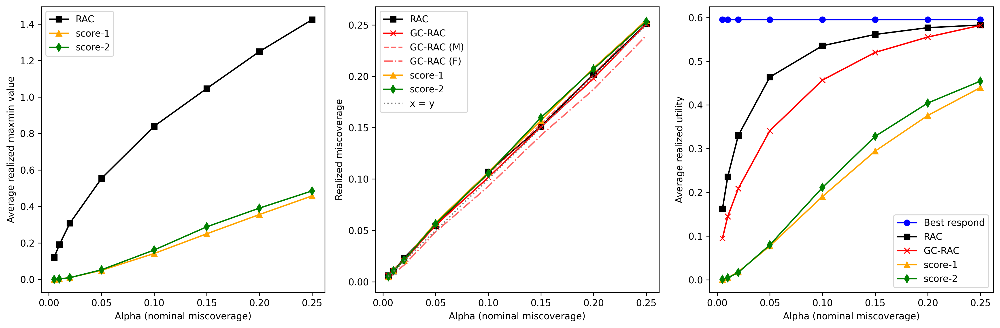

In [25]:
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
import numpy as np

# Example values (you can replace these with your actual data)

alpha_list = [0.005, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25]
# Define consistent colors
colors = {
    'ours': 'black',
    'b': 'blue',
    's1': 'orange',
    's2': 'green',
    'gc': 'red'
}


# Create the plots
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=300, sharey=False)

# Plot 1: Averages
axes[2].plot(alpha_list, avg_b, label='Best respond', marker='o', color=colors['b'])
axes[2].plot(alpha_list, avg_ours, label='RAC', marker='s', color=colors['ours'])
axes[2].plot(alpha_list, avg_gc, label='GC-RAC', marker='x', color=colors['gc'])
axes[2].plot(alpha_list, avg_s1, label='score-1', marker='^', color=colors['s1'])
axes[2].plot(alpha_list, avg_s2, label='score-2', marker='d', color=colors['s2'])
axes[2].set_xlabel('Alpha (nominal miscoverage)')
axes[2].set_ylabel('Average realized utility')
axes[2].legend()
# axes[0].set_xticks(alpha_list)  # Set x-axis ticks to alpha_list

# Plot 2: Q-values
axes[1].plot(alpha_list, q_ours, label='RAC', marker='s', color=colors['ours'])
axes[1].plot(alpha_list, q_gc, label='GC-RAC', marker='x', color=colors['gc'])
axes[1].plot(alpha_list, q_gc_g0, label='GC-RAC (M)', linestyle='--', color=colors['gc'], alpha=0.6)
axes[1].plot(alpha_list, q_gc_g1, label='GC-RAC (F)', linestyle='-.', color=colors['gc'], alpha=0.6)
axes[1].plot(alpha_list, q_s1, label='score-1', marker='^', color=colors['s1'])
axes[1].plot(alpha_list, q_s2, label='score-2', marker='d', color=colors['s2'])

# Add x = y baseline as dotted line
axes[1].plot(alpha_list, alpha_list, label='x = y', linestyle=':', color='gray')

axes[1].set_xlabel('Alpha (nominal miscoverage)')
axes[1].set_ylabel('Realized miscoverage')
# axes[1].set_title('Plot of Q-values')
axes[1].legend()
# axes[1].set_xticks(alpha_list)  # Set x-axis ticks to alpha_list

# Plot 3: Maximums
axes[0].plot(alpha_list, max_ours, label='RAC', marker='s', color=colors['ours'])
axes[0].plot(alpha_list, max_s1, label='score-1', marker='^', color=colors['s1'])
axes[0].plot(alpha_list, max_s2, label='score-2', marker='d', color=colors['s2'])
axes[0].set_xlabel('Alpha (nominal miscoverage)')
axes[0].set_ylabel('Average realized maxmin value')
axes[0].legend()
# axes[2].set_xticks(alpha_list)  # Set x-axis ticks to alpha_list

# Adjust layout
plt.tight_layout()

# Save the figure
plt.savefig("icml_three_plots.pdf")
plt.show()


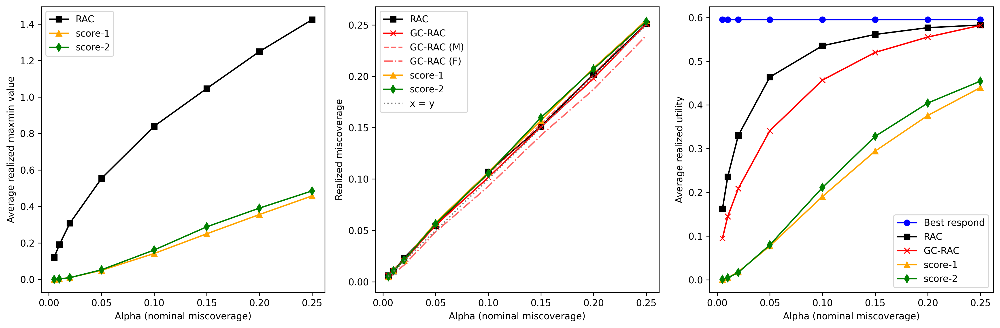

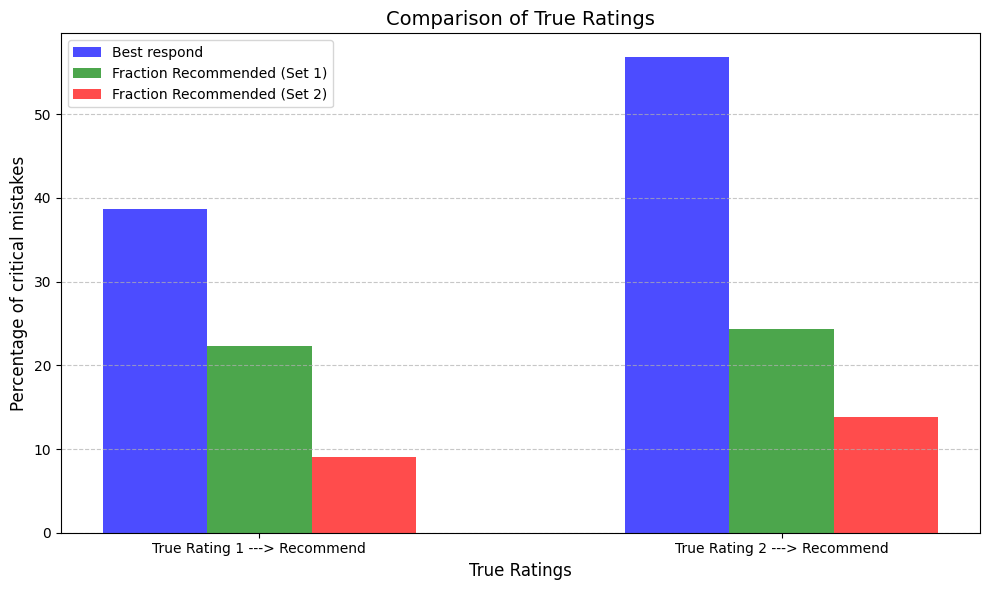

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Data for True Ratings
true_rating_labels = ["True Rating 1 ---> Recommend", "True Rating 2 ---> Recommend"]

# The following numbers are for the specific setup that is used for the paper.
#To reproduce this, or compute them for your own setup, you have to run the method of your interest with the specific value of alpha and then read the results and plug them in here.
#To run each of the methods, right after each method's implementaion in this file, there is an exmample, which helps you run the method.

true_rating_percent = [38.63, 56.83]
true_rating_fraction1 = [143/642 *100, 290/1193* 100]
true_rating_fraction2 = [58/642* 100, 165/1193* 100]



# Combine all data for plotting
bar_width = 0.2
x = np.arange(len(true_rating_labels))

plt.figure(figsize=(10, 6))

# Plot bars for Percentage
plt.bar(x - bar_width, true_rating_percent, width=bar_width, label='Best respond', color='blue', alpha=0.7)

# Plot bars for Fraction 1
plt.bar(x, true_rating_fraction1, width=bar_width, label='Fraction Recommended (Set 1)', color='green', alpha=0.7)

# Plot bars for Fraction 2
plt.bar(x + bar_width, true_rating_fraction2, width=bar_width, label='Fraction Recommended (Set 2)', color='red', alpha=0.7)

# Add labels and title
plt.xlabel('True Ratings', fontsize=12)
plt.ylabel('Percentage of critical mistakes', fontsize=12)
plt.title('Comparison of True Ratings', fontsize=14)
plt.xticks(ticks=x, labels=true_rating_labels)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()


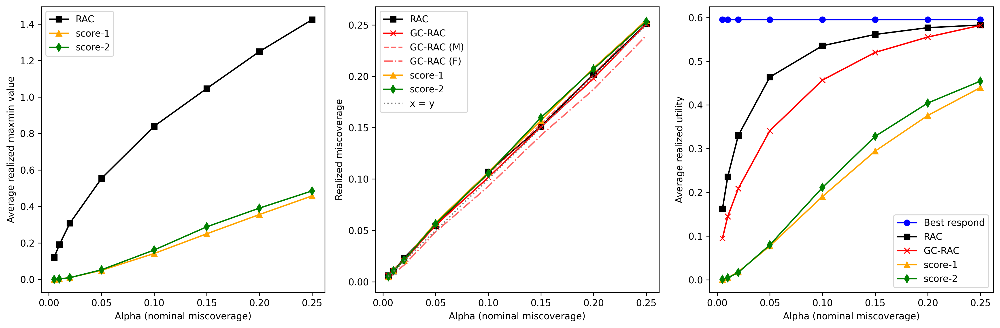

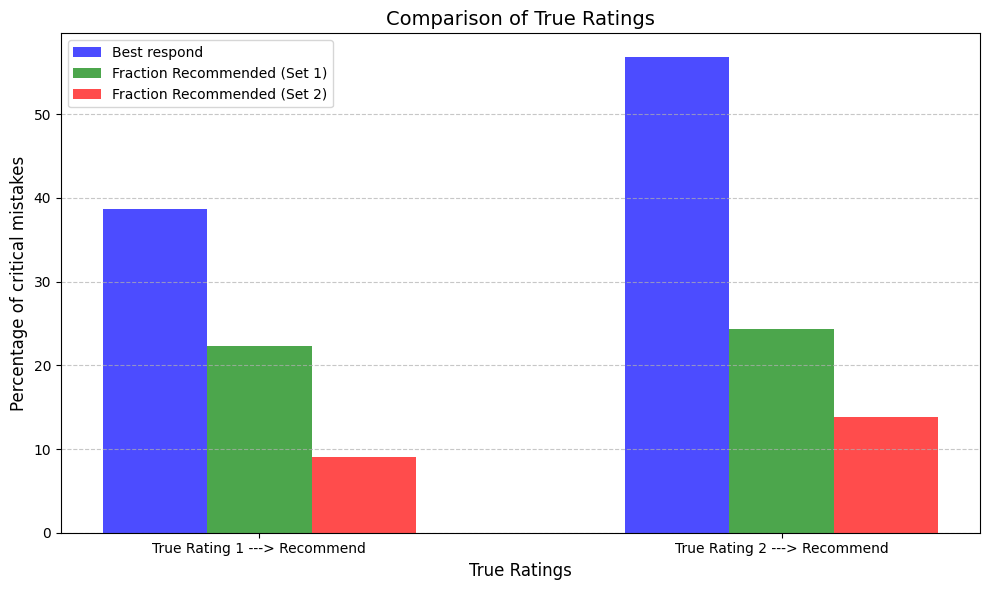

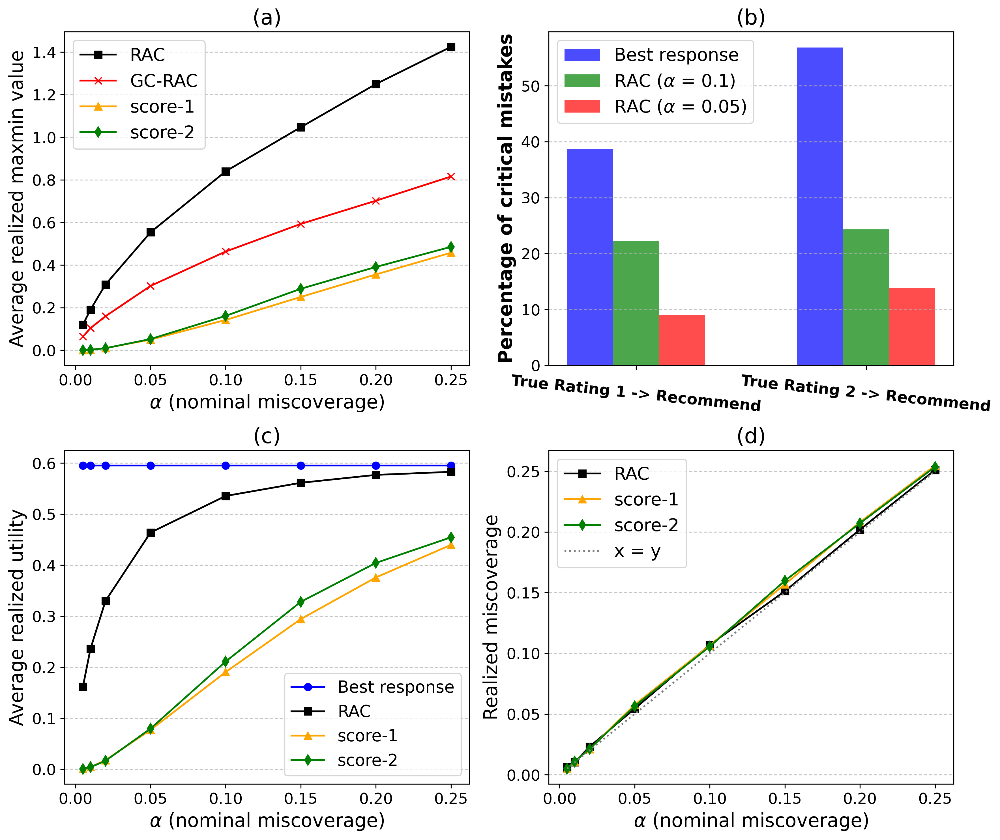

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# Example values (you can replace these with your actual data)
alpha_list = [0.005, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25]
# Define consistent colors
colors = {
    'ours': 'black',
    'b': 'blue',
    's1': 'orange',
    's2': 'green',
    'gc': 'red'
}

# The following numbers are for the specific setup that is used for the paper.
#To reproduce this, or compute them for your own setup, you have to run the method of your interest with the specific value of alpha and then read the results and plug them in here.
#To run each of the methods, right after each method's implementaion in this file, there is an exmample, which helps you run the method.



# Data for True Ratings
true_rating_labels = ["True Rating 1 -> Recommend", "True Rating 2 -> Recommend"]
true_rating_percent = [38.63, 56.83]
true_rating_fraction1 = [143/642 * 100, 290/1193 * 100]
true_rating_fraction2 = [58/642 * 100, 165/1193 * 100]

# Combine all data for plotting
bar_width = 0.2
x = np.arange(len(true_rating_labels))

# Create a 2x2 grid of plots
fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=300)

# Plot 1: Maximums
axes[0, 0].plot(alpha_list, max_ours, label='RAC', marker='s', color=colors['ours'])
axes[0, 0].plot(alpha_list, max_gc, label='GC-RAC', marker='x', color=colors['gc'])
axes[0, 0].plot(alpha_list, max_s1, label='score-1', marker='^', color=colors['s1'])
axes[0, 0].plot(alpha_list, max_s2, label='score-2', marker='d', color=colors['s2'])
axes[0, 0].set_xlabel(r'$\alpha$ (nominal miscoverage)', fontsize = 16)
axes[0, 0].set_ylabel('Average realized maxmin value', fontsize = 16)
axes[0, 0].legend(fontsize = 15)
axes[0, 0].grid(axis='y', linestyle='--', alpha=0.7)
axes[0, 0].set_title('(a)', fontsize=18)

# Plot 2: Q-values
axes[1, 1].plot(alpha_list, q_ours, label='RAC', marker='s', color=colors['ours'])
axes[1, 1].plot(alpha_list, q_s1, label='score-1', marker='^', color=colors['s1'])
axes[1, 1].plot(alpha_list, q_s2, label='score-2', marker='d', color=colors['s2'])
axes[1, 1].plot(alpha_list, alpha_list, label='x = y', linestyle=':', color='gray')
axes[1, 1].set_xlabel(r'$\alpha$ (nominal miscoverage)', fontsize = 16)
axes[1, 1].set_ylabel('Realized miscoverage', fontsize = 16)
axes[1, 1].legend(fontsize = 15)
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.7)
axes[1, 1].set_title('(d)', fontsize=18)

# Plot 3: Averages
axes[1, 0].plot(alpha_list, avg_b, label='Best response', marker='o', color=colors['b'])
axes[1, 0].plot(alpha_list, avg_ours, label='RAC', marker='s', color=colors['ours'])
axes[1, 0].plot(alpha_list, avg_s1, label='score-1', marker='^', color=colors['s1'])
axes[1, 0].plot(alpha_list, avg_s2, label='score-2', marker='d', color=colors['s2'])
axes[1, 0].set_xlabel(r'$\alpha$ (nominal miscoverage)', fontsize = 16)
axes[1, 0].set_ylabel('Average realized utility', fontsize = 16)
axes[1, 0].legend(fontsize = 14)
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.7)
axes[1, 0].set_title('(c)', fontsize=18)

# Plot 4: True Ratings Comparison
axes[0, 1].bar(x - bar_width, true_rating_percent, width=bar_width, label='Best response', color='blue', alpha=0.7)
axes[0, 1].bar(x, true_rating_fraction1, width=bar_width, label=r'RAC ($\alpha$ = 0.1)', color='green', alpha=0.7)
axes[0, 1].bar(x + bar_width, true_rating_fraction2, width=bar_width, label=r'RAC ($\alpha$ = 0.05)', color='red', alpha=0.7)
axes[0, 1].set_title('(b)', fontsize=18)
axes[0, 1].set_ylabel('Percentage of critical mistakes', fontsize=16, fontweight='bold')
axes[0, 1].set_xticks(ticks=x)
axes[0, 1].set_xticklabels(true_rating_labels, fontsize= 12, fontweight='bold', rotation = -6)
axes[0, 1].legend(fontsize = 15)
axes[0, 1].grid(axis='y', linestyle='--', alpha=0.7)

for ax in axes.flat:
    ax.tick_params(axis='both', labelsize=13)  # Increase font size of both x and y ticks
# axes[0, 1].set_xticklabels(true_rating_labels, fontsize= 11, fontweight='bold', rotation = -4)

# Adjust layout
plt.tight_layout()
plt.savefig("icml_2x2_plots_movie.pdf")
plt.show()


In [28]:
OUT_DIR = "group_conditional_gender"
os.makedirs(OUT_DIR, exist_ok=True)

print(f"Saving plots to: {OUT_DIR}/")

Saving plots to: group_conditional_gender/


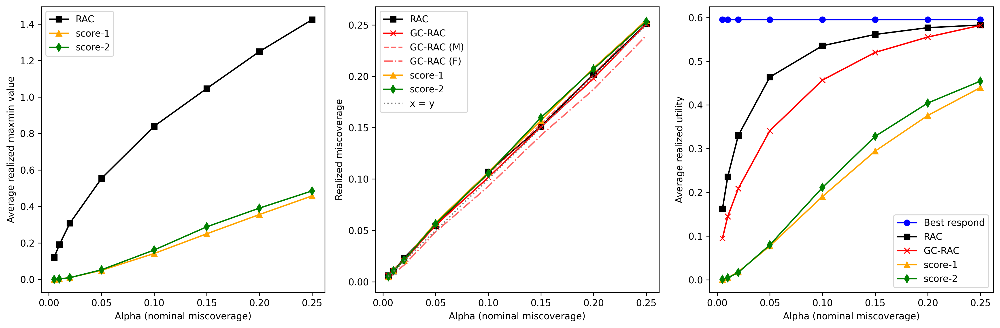

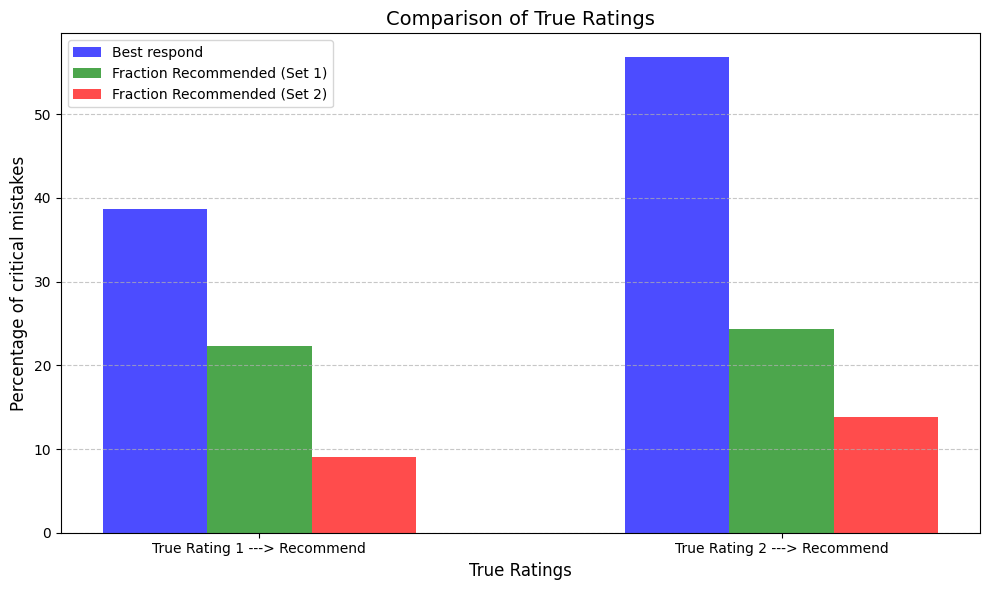

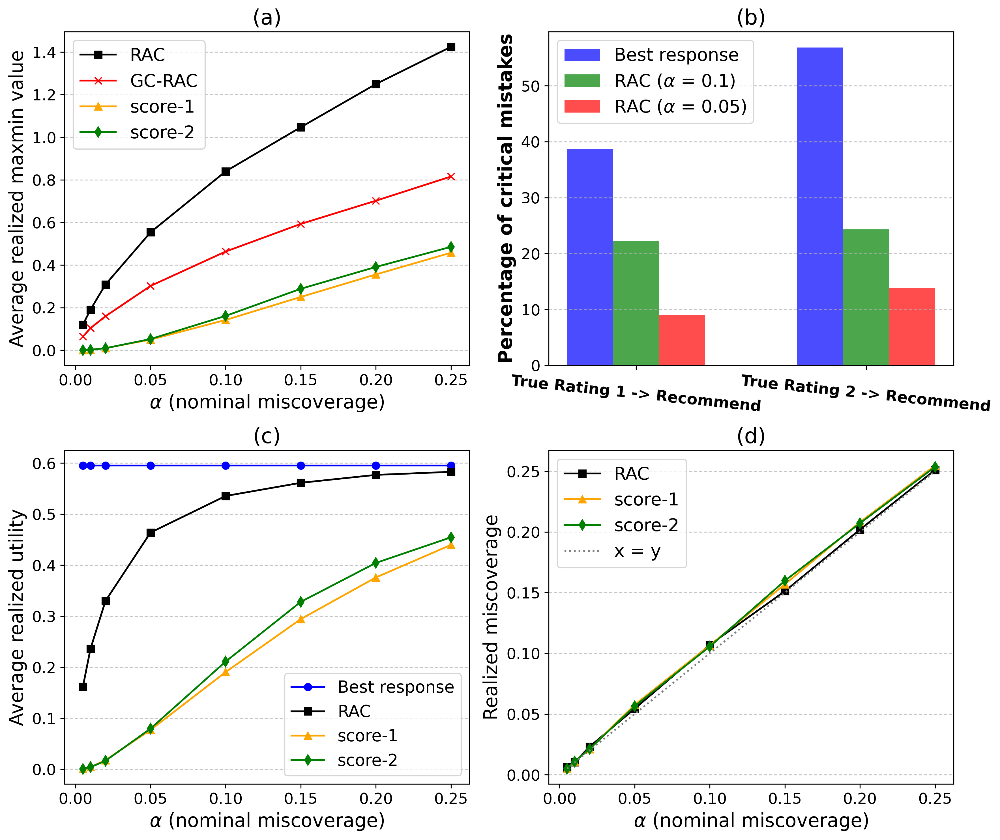

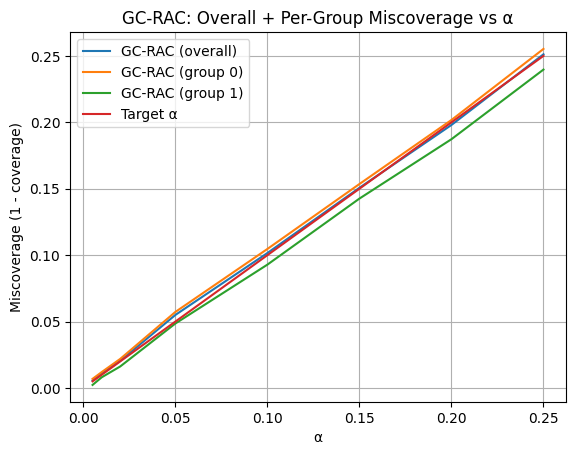

In [29]:
# Per-group miscoverage vs α
alphas = np.array(alpha_list)   # <-- ADD THIS LINE

plt.figure()
plt.plot(alphas, q_gc, label="GC-RAC (overall)")
plt.plot(alphas, q_gc_g0, label="GC-RAC (group 0)")
plt.plot(alphas, q_gc_g1, label="GC-RAC (group 1)")
plt.plot(alphas, alphas, label="Target α")
plt.xlabel("α")
plt.ylabel("Miscoverage (1 - coverage)")
plt.title("GC-RAC: Overall + Per-Group Miscoverage vs α")
plt.grid(True)
plt.legend()
plt.show()

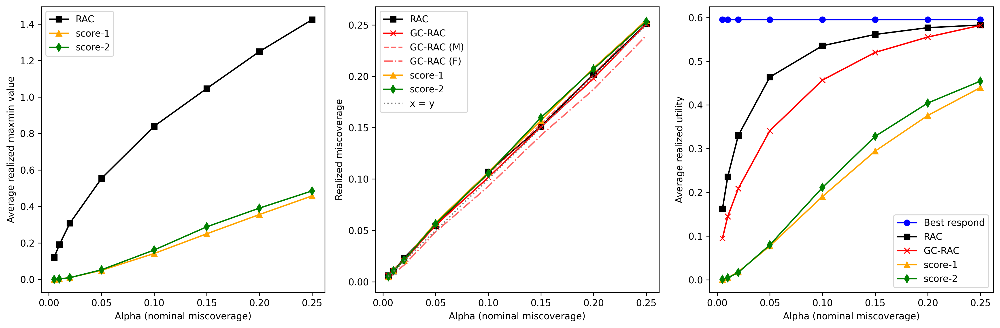

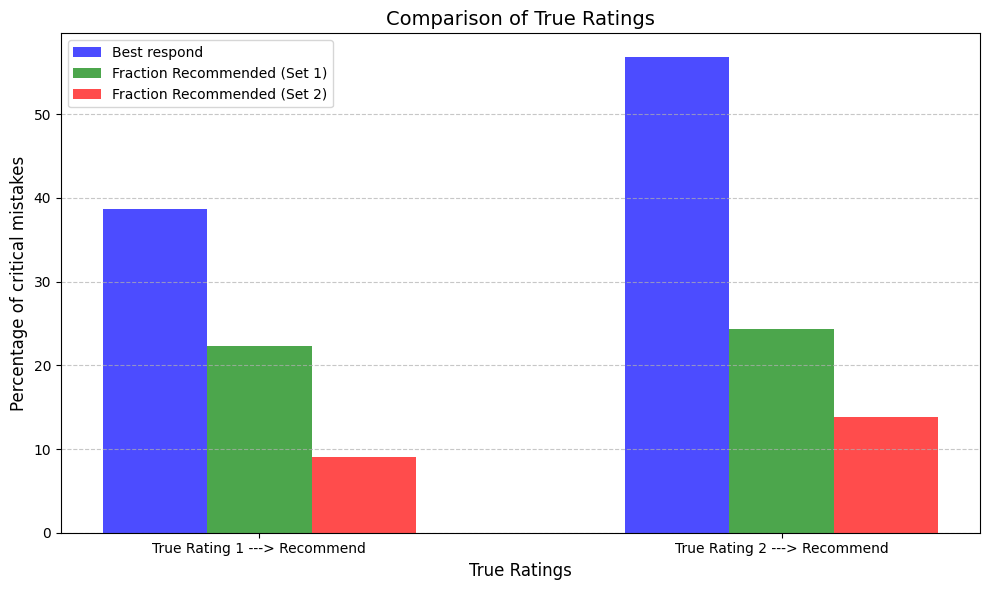

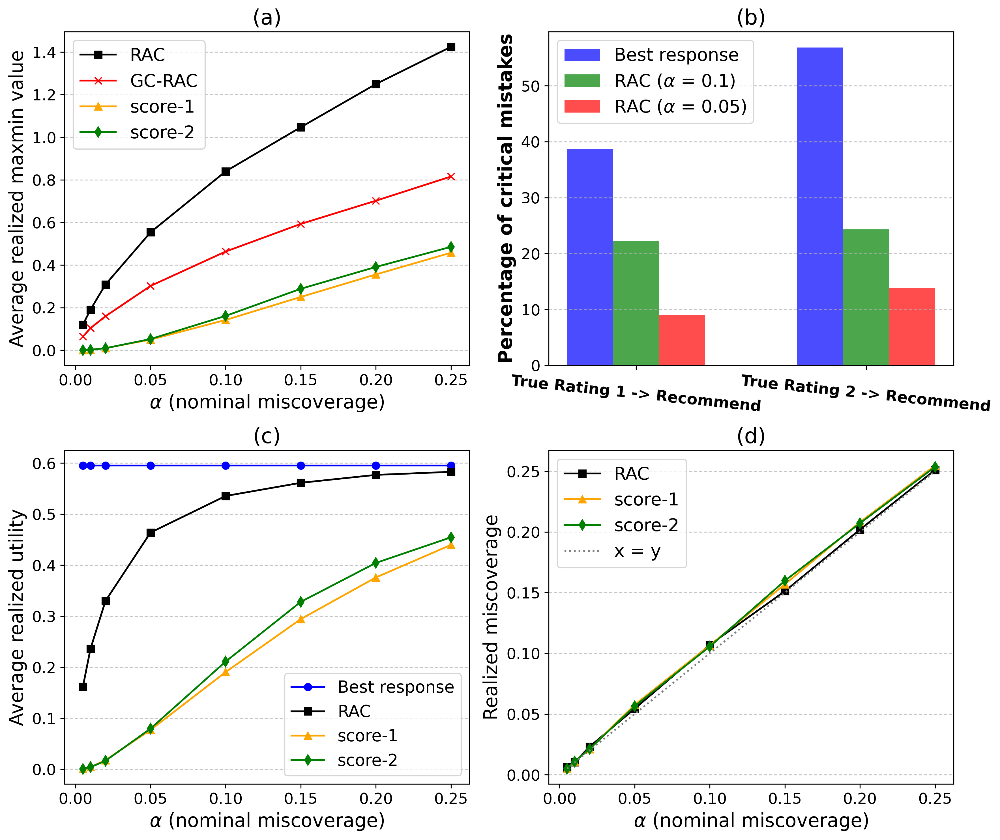

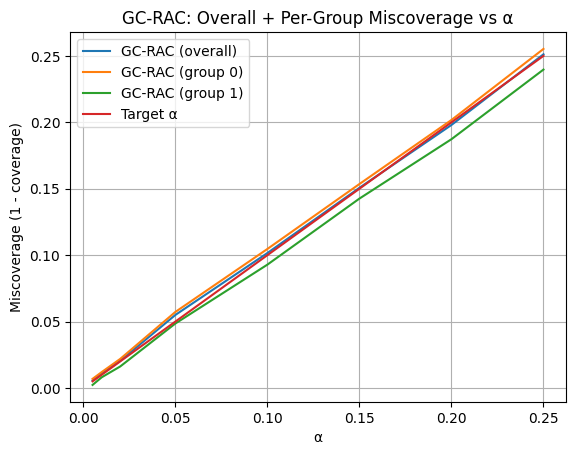

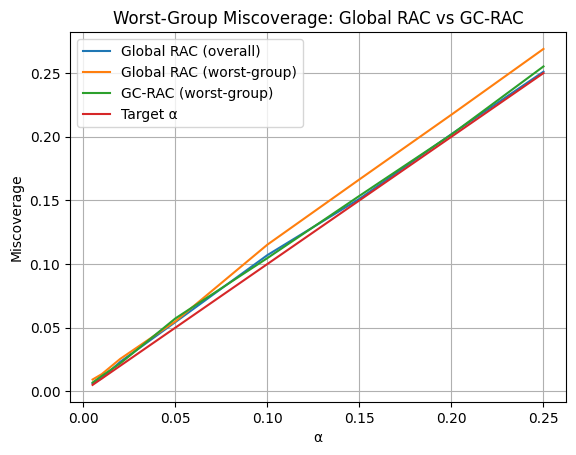

In [30]:
OUT_DIR = "group_conditional_gender"
os.makedirs(OUT_DIR, exist_ok=True)

alphas = np.array(alpha_list)

# Worst-group miscoverage
worst_gc    = np.maximum(np.array(q_gc_g0),    np.array(q_gc_g1))
worst_ours  = np.maximum(np.array(q_ours_g0), np.array(q_ours_g1))

plt.figure()
plt.plot(alphas, q_ours, label="Global RAC (overall)")
plt.plot(alphas, worst_ours, label="Global RAC (worst-group)")
plt.plot(alphas, worst_gc, label="GC-RAC (worst-group)")
plt.plot(alphas, alphas, label="Target α")

plt.xlabel("α")
plt.ylabel("Miscoverage")
plt.title("Worst-Group Miscoverage: Global RAC vs GC-RAC")
plt.grid(True)
plt.legend()

plt.savefig(f"{OUT_DIR}/worst_group_vs_global.png", dpi=200, bbox_inches="tight")
plt.savefig(f"{OUT_DIR}/worst_group_vs_global.pdf", bbox_inches="tight")
plt.show()

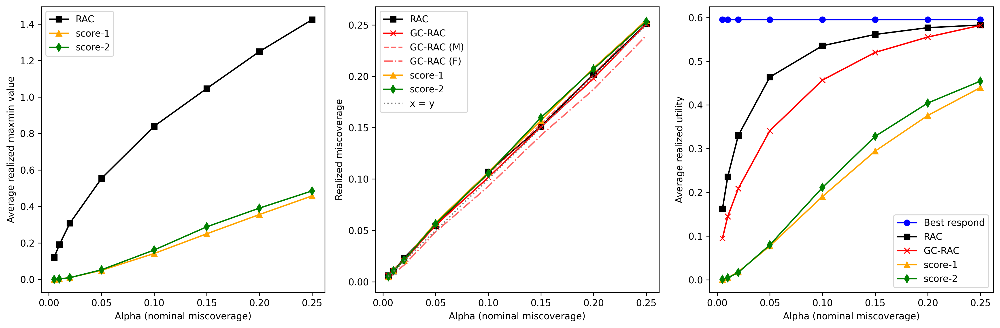

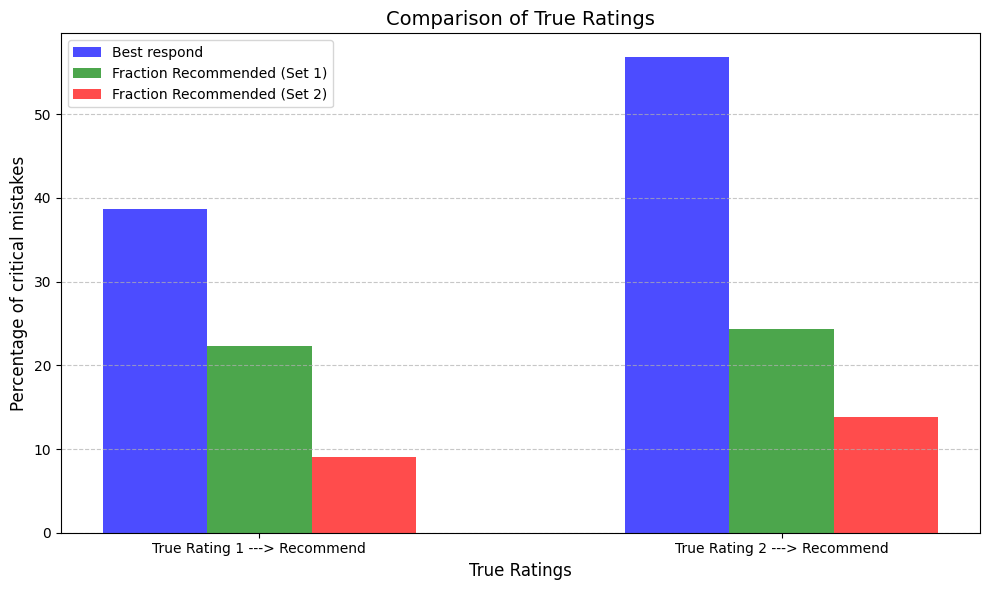

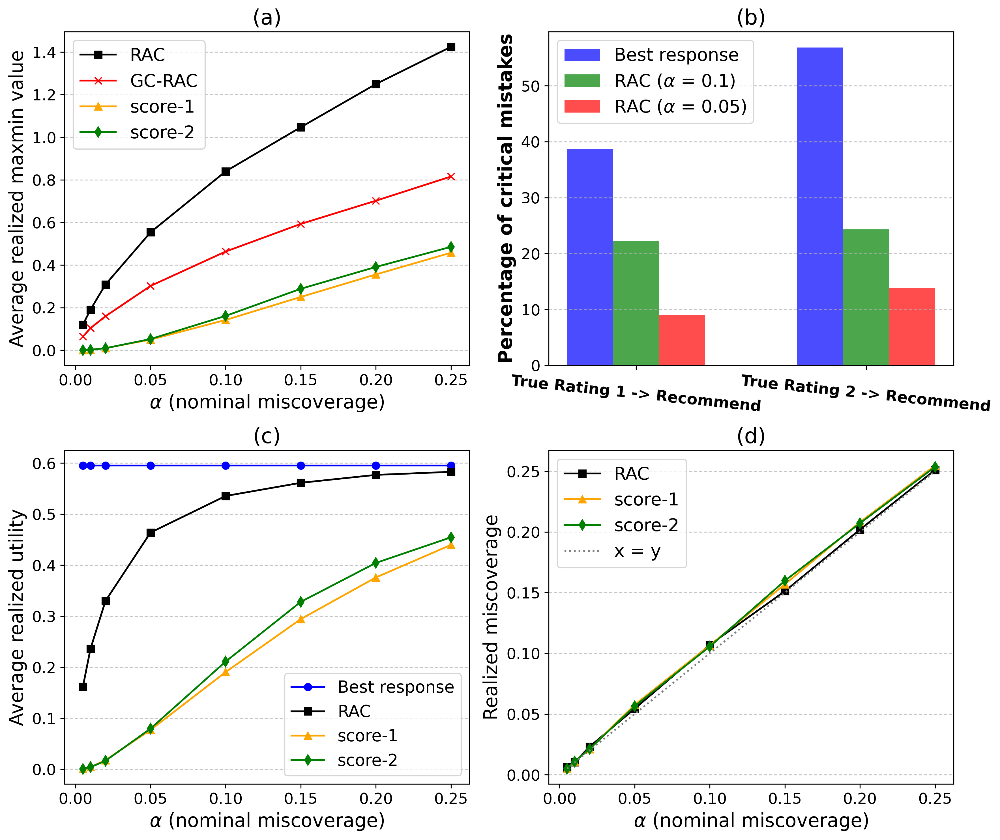

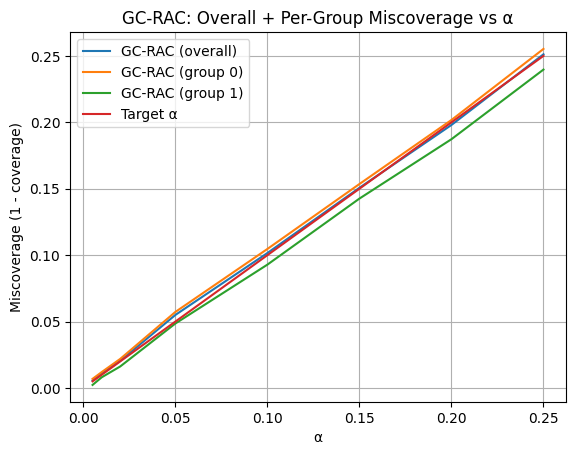

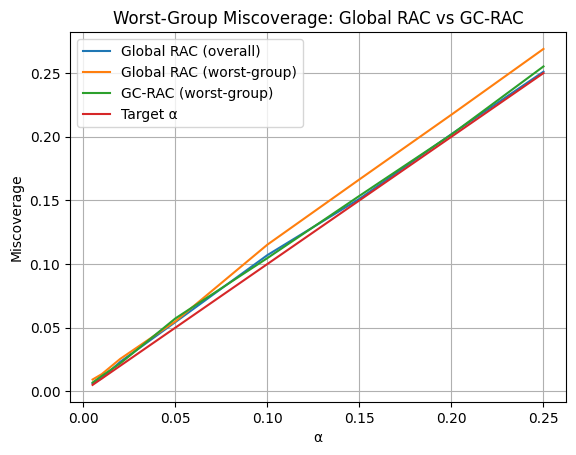

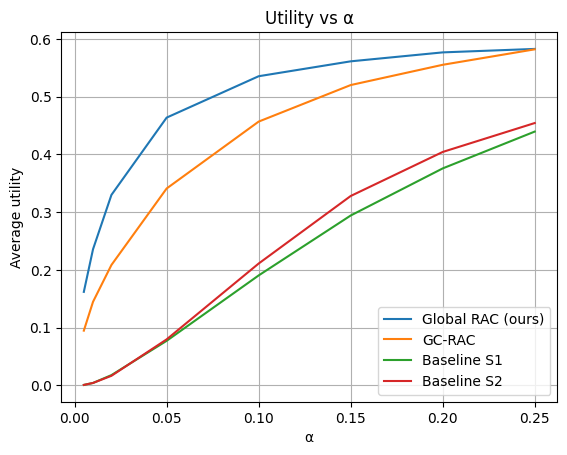

In [31]:
OUT_DIR = "group_conditional_gender"
os.makedirs(OUT_DIR, exist_ok=True)

alphas = np.array(alpha_list)

plt.figure()
plt.plot(alphas, avg_ours, label="Global RAC (ours)")
plt.plot(alphas, avg_gc, label="GC-RAC")
plt.plot(alphas, avg_s1, label="Baseline S1")
plt.plot(alphas, avg_s2, label="Baseline S2")
plt.xlabel("α")
plt.ylabel("Average utility")
plt.title("Utility vs α")
plt.grid(True)
plt.legend()

plt.savefig(f"{OUT_DIR}/utility_vs_alpha.png", dpi=200, bbox_inches="tight")
plt.savefig(f"{OUT_DIR}/utility_vs_alpha.pdf", bbox_inches="tight")
plt.show()

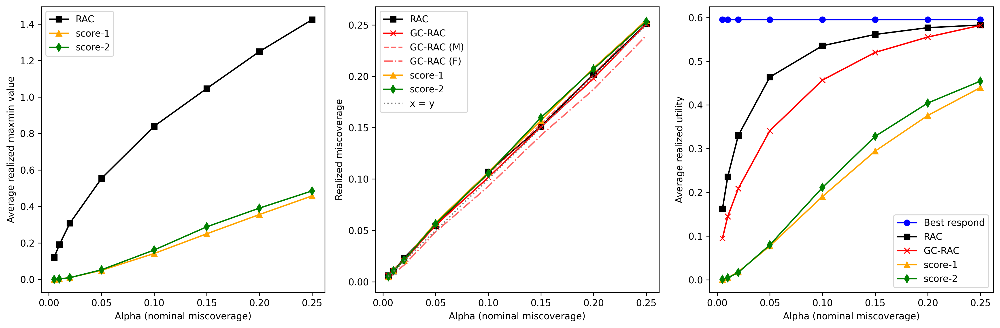

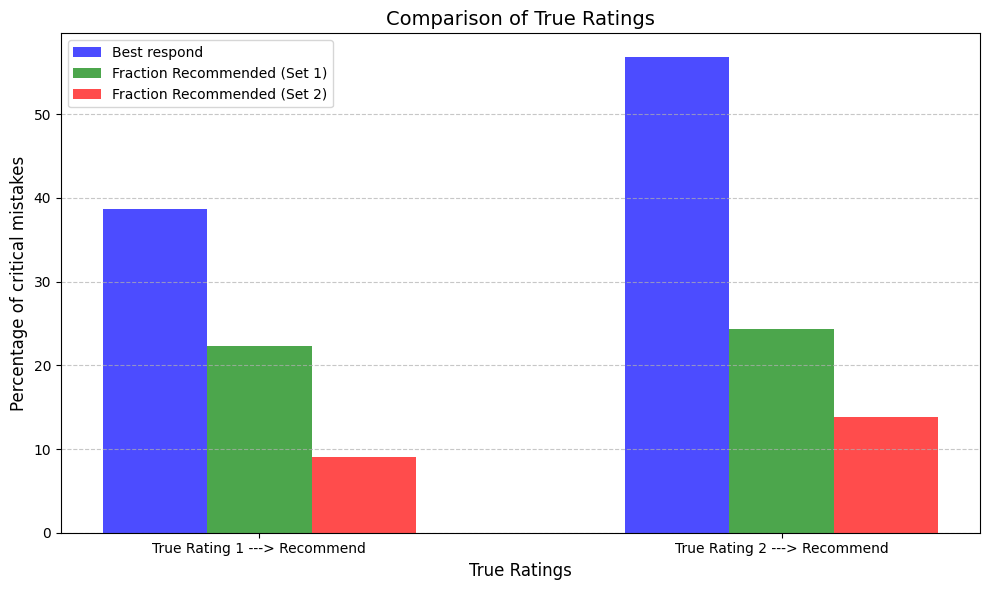

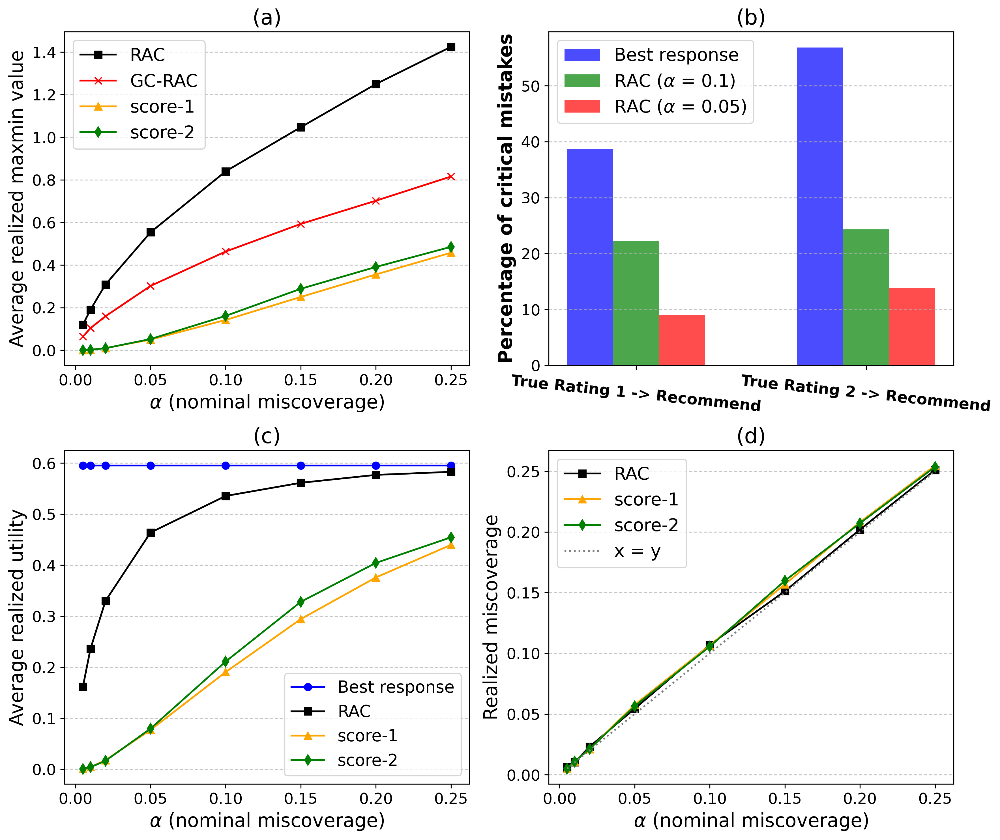

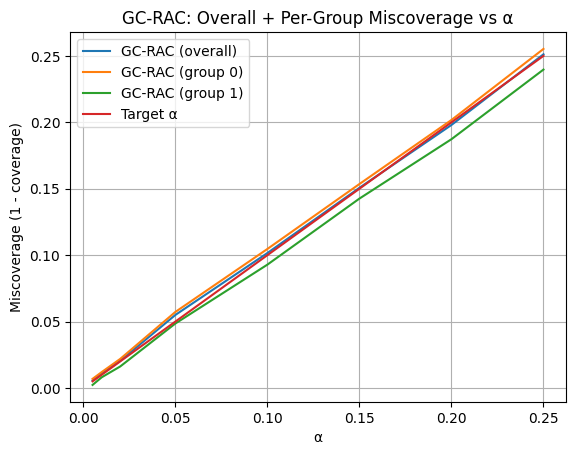

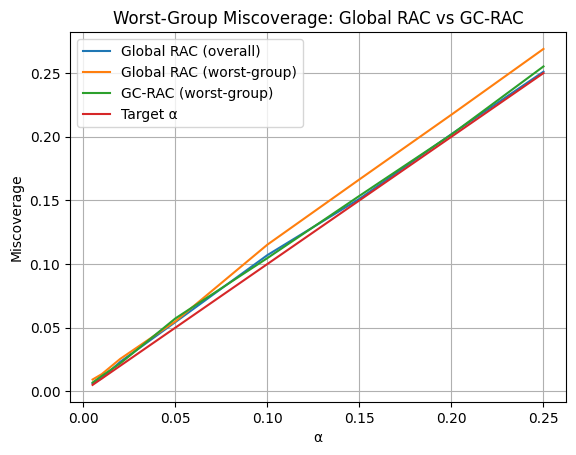

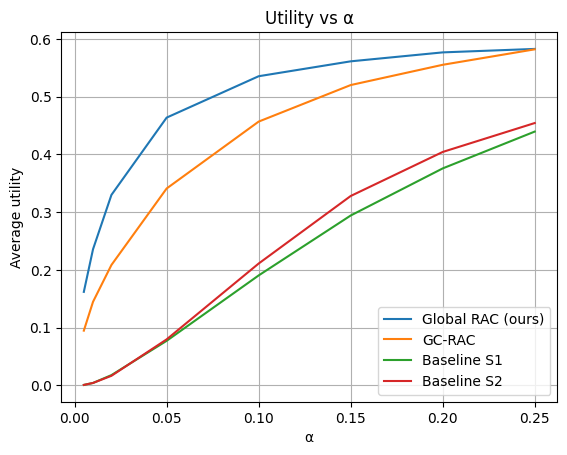

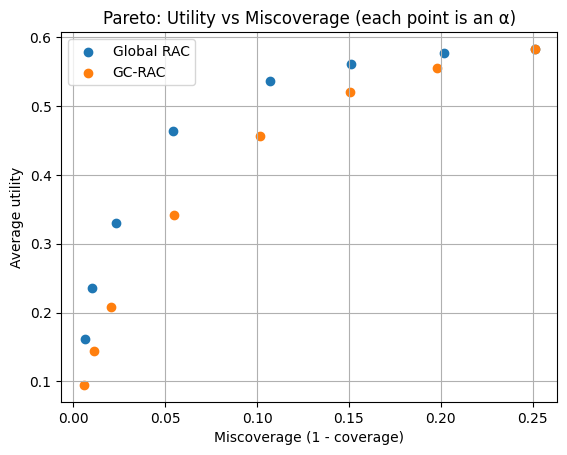

In [32]:
OUT_DIR = "group_conditional_gender"
os.makedirs(OUT_DIR, exist_ok=True)

plt.figure()
plt.scatter(q_ours, avg_ours, label="Global RAC")
plt.scatter(q_gc, avg_gc, label="GC-RAC")
plt.xlabel("Miscoverage (1 - coverage)")
plt.ylabel("Average utility")
plt.title("Pareto: Utility vs Miscoverage (each point is an α)")
plt.grid(True)
plt.legend()

plt.savefig(f"{OUT_DIR}/pareto_utility_vs_miscoverage.png", dpi=200, bbox_inches="tight")
plt.savefig(f"{OUT_DIR}/pareto_utility_vs_miscoverage.pdf", bbox_inches="tight")
plt.show()

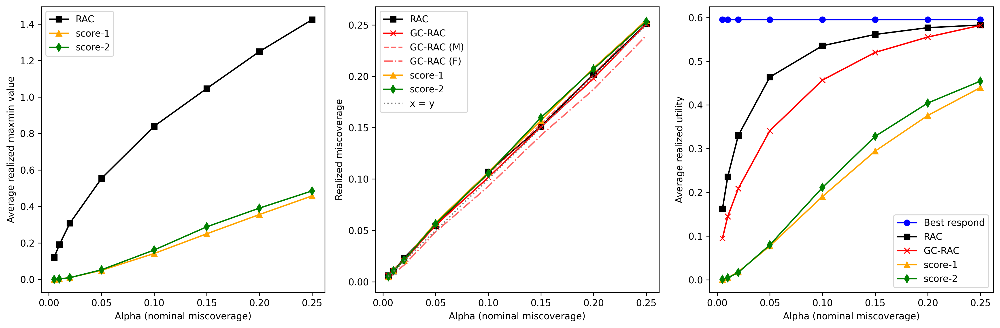

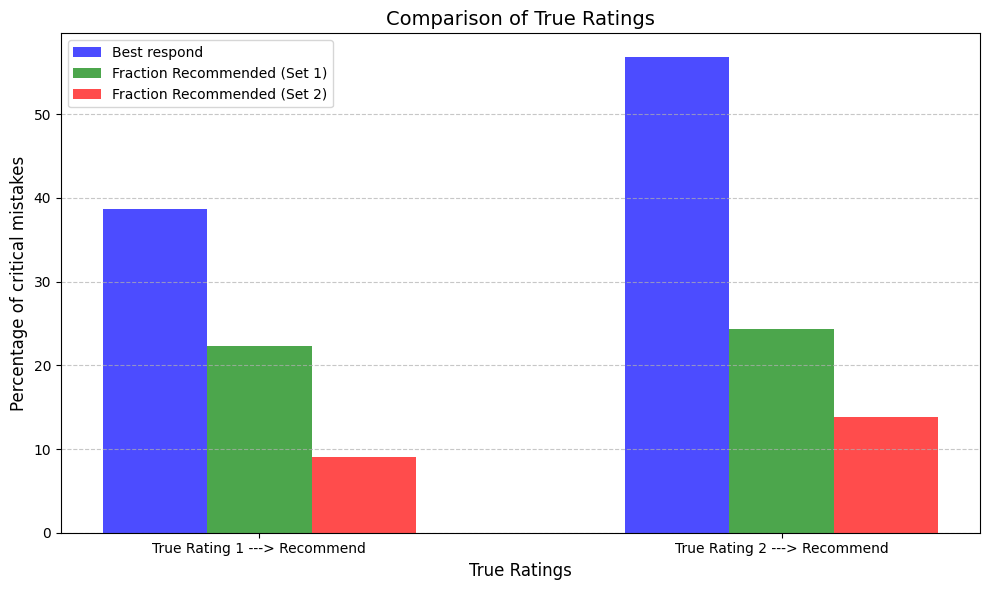

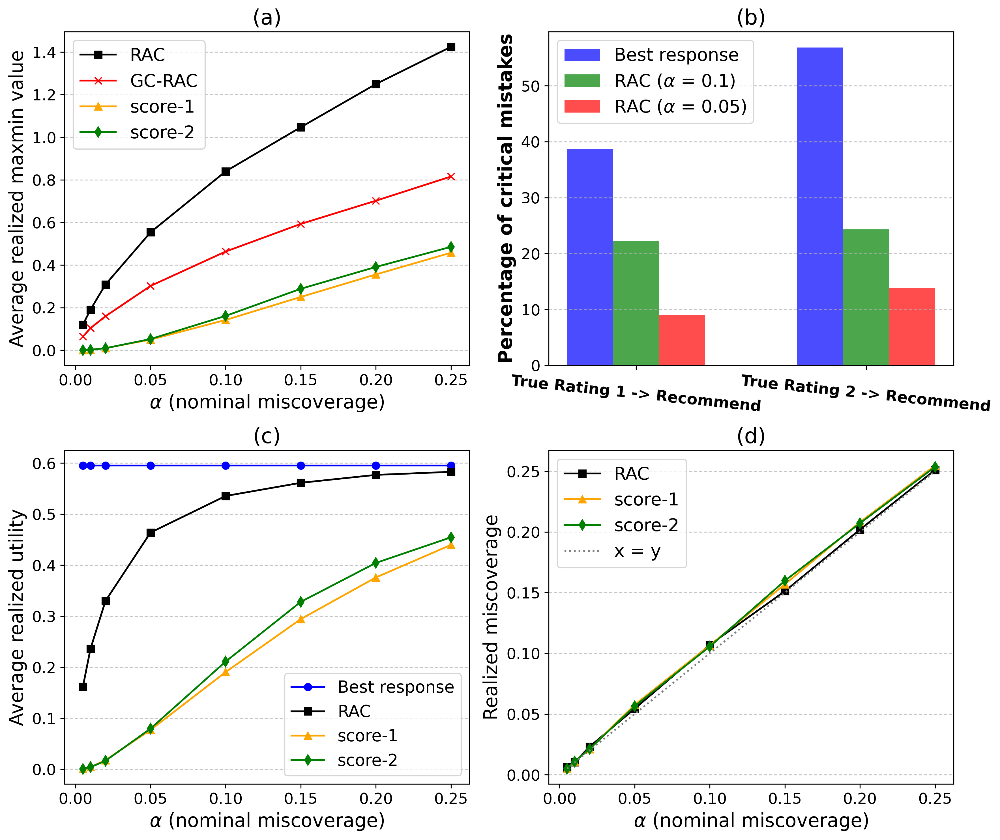

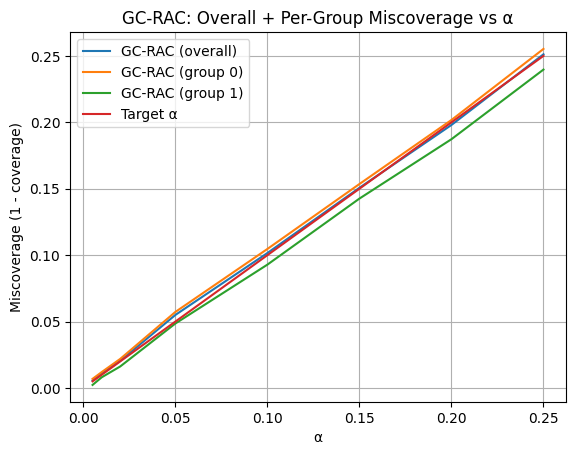

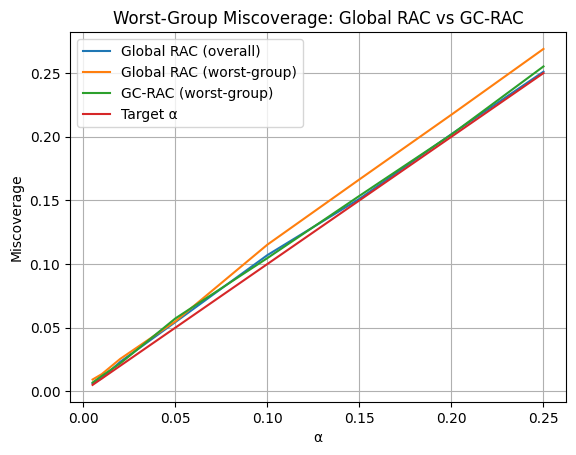

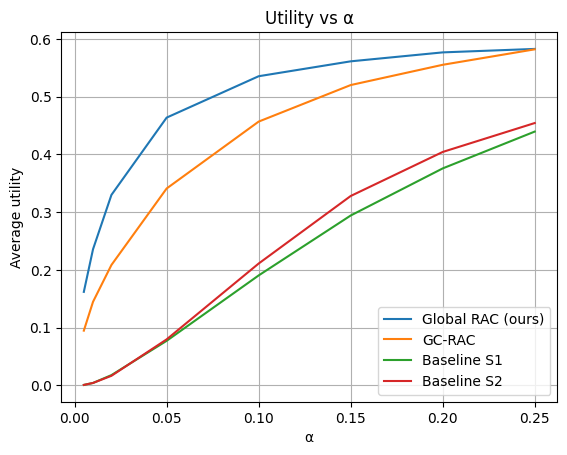

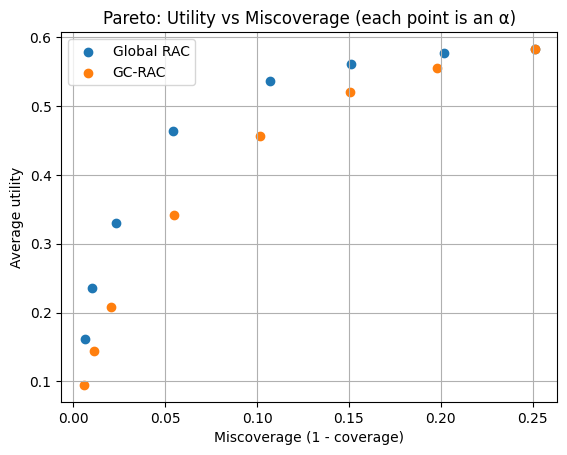

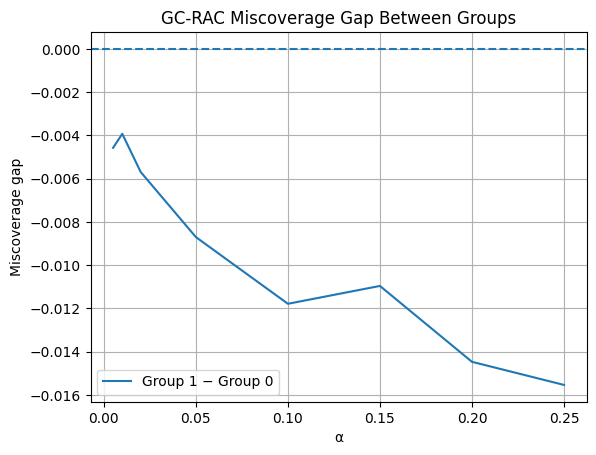

In [33]:
OUT_DIR = "group_conditional_gender"
os.makedirs(OUT_DIR, exist_ok=True)

alphas = np.array(alpha_list)
gap = np.array(q_gc_g1) - np.array(q_gc_g0)

plt.figure()
plt.plot(alphas, gap, label="Group 1 − Group 0")
plt.axhline(0.0, linestyle="--")
plt.xlabel("α")
plt.ylabel("Miscoverage gap")
plt.title("GC-RAC Miscoverage Gap Between Groups")
plt.grid(True)
plt.legend()

plt.savefig(f"{OUT_DIR}/miscoverage_gap_between_groups.png", dpi=200, bbox_inches="tight")
plt.savefig(f"{OUT_DIR}/miscoverage_gap_between_groups.pdf", bbox_inches="tight")
plt.show()

In [34]:
OUT_DIR = "group_conditional_gender"
os.makedirs(OUT_DIR, exist_ok=True)

alphas = np.array(alpha_list)

df = pd.DataFrame({
    "alpha": alphas,
    "global_miscoverage": np.array(q_ours),
    "gc_overall_miscoverage": np.array(q_gc),
    "gc_g0_miscoverage": np.array(q_gc_g0),
    "gc_g1_miscoverage": np.array(q_gc_g1),
})
df["gc_worst_group"] = np.maximum(df["gc_g0_miscoverage"], df["gc_g1_miscoverage"])

df["global_violate"] = df["global_miscoverage"] > df["alpha"]
df["gc_g0_violate"] = df["gc_g0_miscoverage"] > df["alpha"]
df["gc_g1_violate"] = df["gc_g1_miscoverage"] > df["alpha"]
df["gc_any_violate"] = df["gc_g0_violate"] | df["gc_g1_violate"]

display(df)
df.to_csv(f"{OUT_DIR}/violations_table.csv", index=False)
print(f"Saved: {OUT_DIR}/violations_table.csv")

,alpha,global_miscoverage,gc_overall_miscoverage,gc_g0_miscoverage,gc_g1_miscoverage,gc_worst_group,global_violate,gc_g0_violate,gc_g1_violate,gc_any_violate
0,0.005,0.0061,0.0057,0.006887,0.002312,0.006887,True,True,False,True
1,0.010,0.0103,0.0110,0.012019,0.008092,0.012019,True,True,False,True
2,0.020,0.0231,0.0204,0.021877,0.016185,0.021877,True,True,False,True
3,0.050,0.0544,0.0550,0.057259,0.048555,0.057259,True,True,False,True
4,0.100,0.1070,0.1016,0.104659,0.092871,0.104659,True,True,False,True
5,0.150,0.1512,0.1507,0.153545,0.142582,0.153545,True,True,False,True
6,0.200,0.2020,0.1980,0.201756,0.187283,0.201756,True,True,False,True
7,0.250,0.2511,0.2512,0.255233,0.239692,0.255233,True,True,False,True


Saved: group_conditional_gender/violations_table.csv


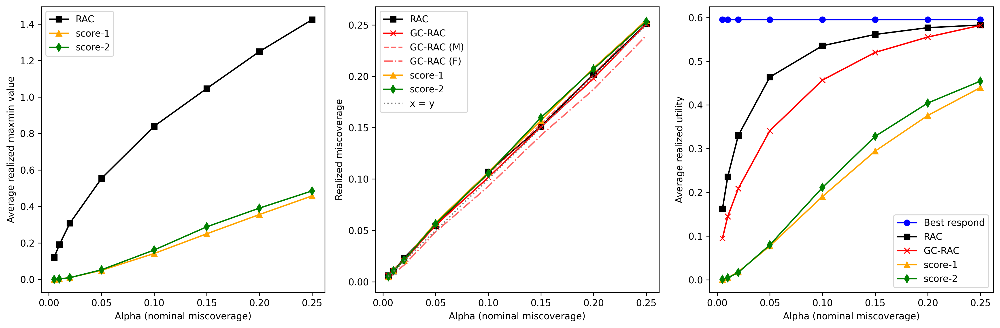

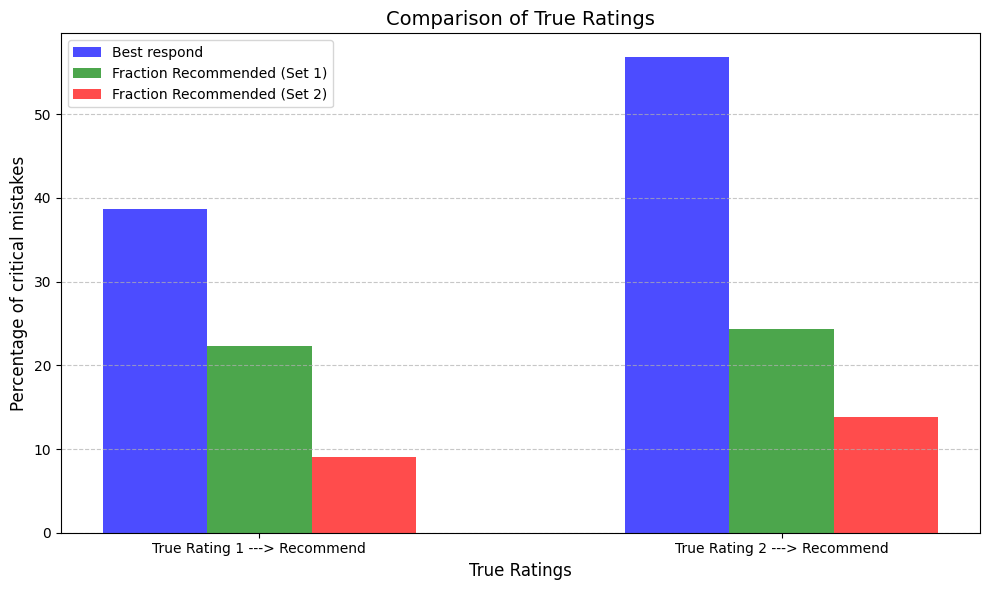

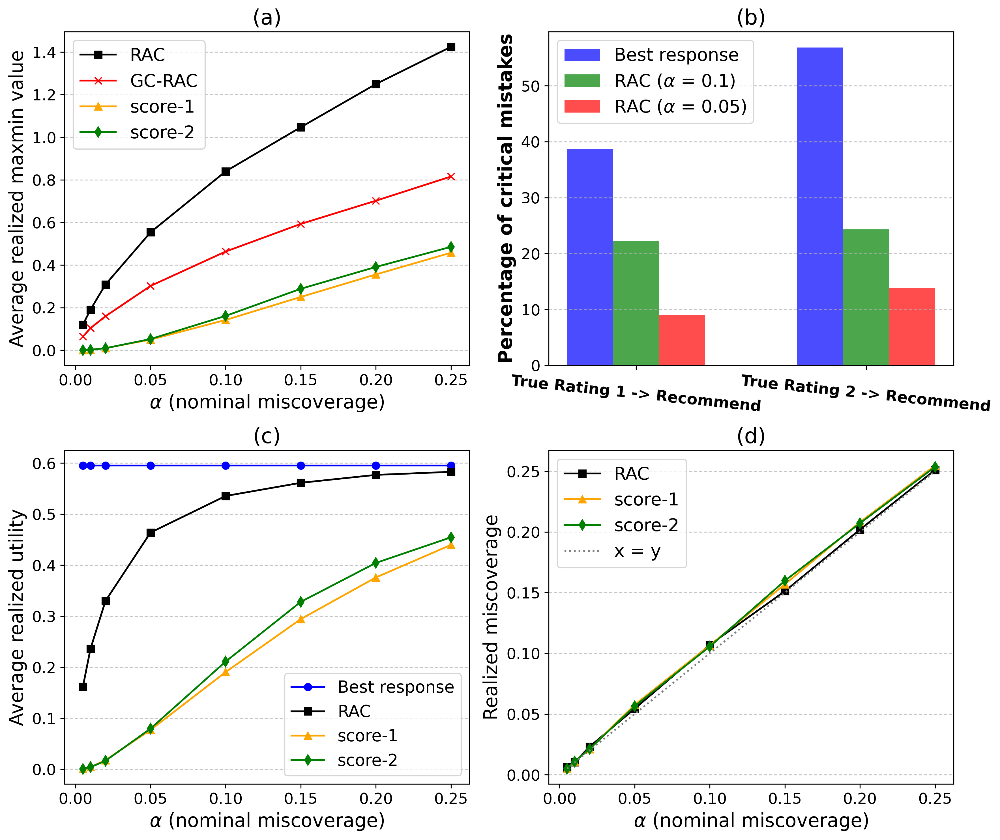

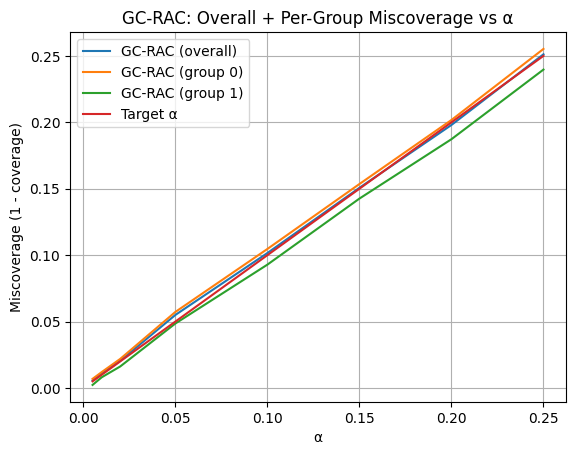

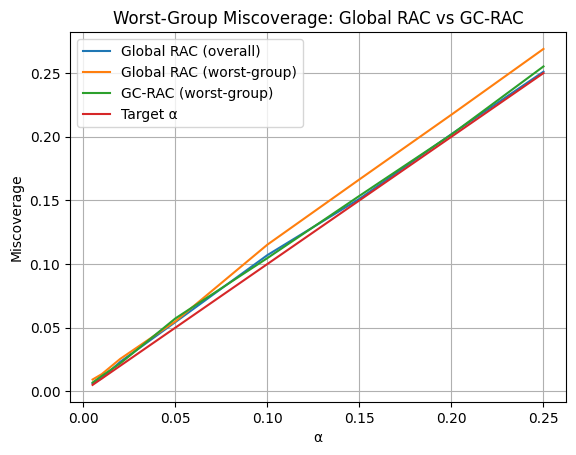

...

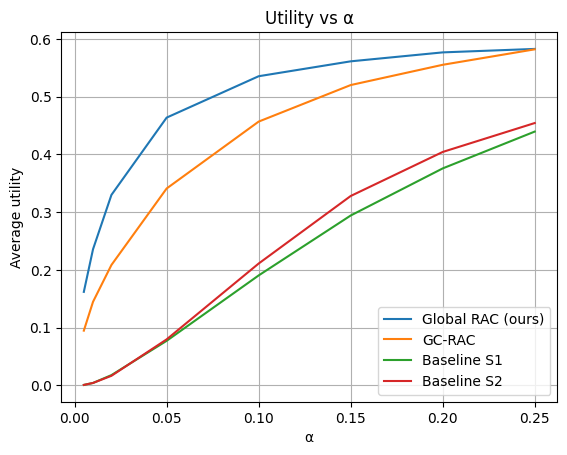

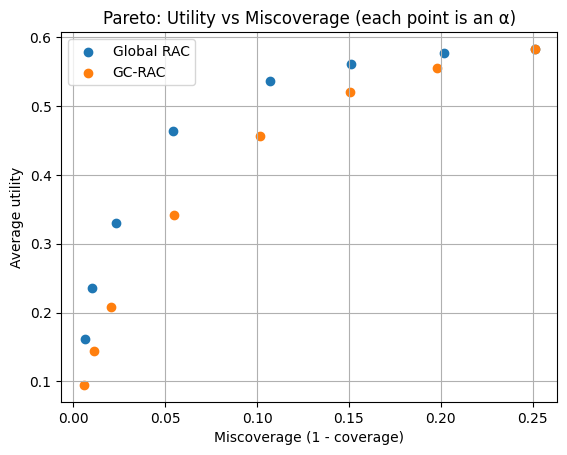

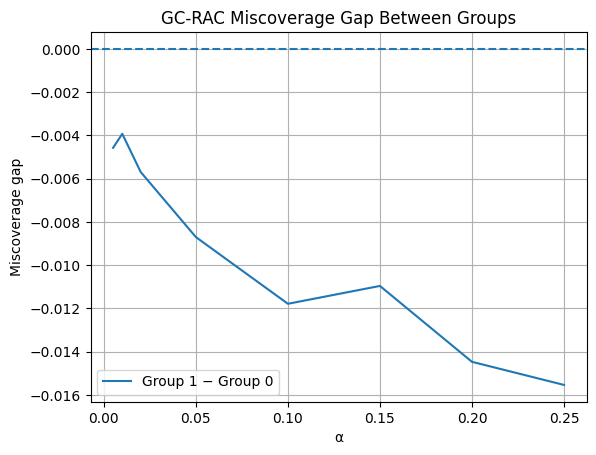

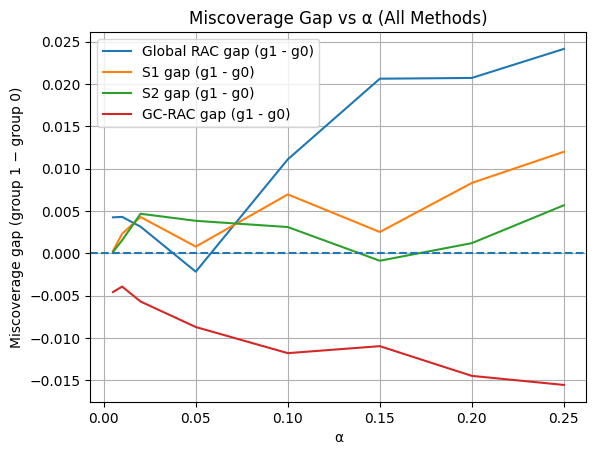

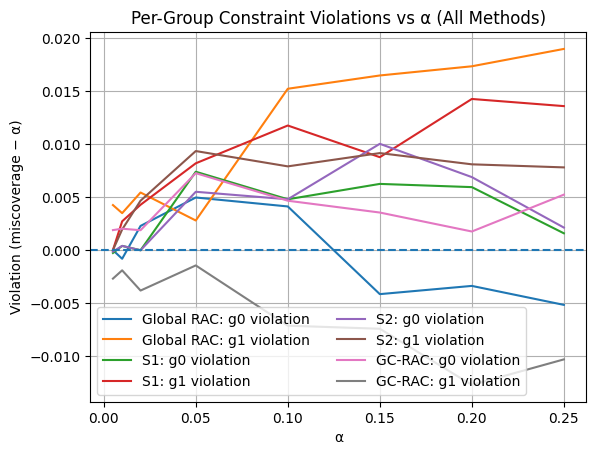

In [35]:
###############################################################################
# NEW: Miscoverage gap + per-group violations for ALL methods (Global, S1, S2, GC)
###############################################################################
import numpy as np
import matplotlib.pyplot as plt
import os

OUT_DIR = "group_conditional_gender"
os.makedirs(OUT_DIR, exist_ok=True)

alphas = np.array(alpha_list)

# Miscoverage gaps (group1 - group0)
gap_ours = np.array(q_ours_g1) - np.array(q_ours_g0)
gap_s1   = np.array(q_s1_g1)   - np.array(q_s1_g0)
gap_s2   = np.array(q_s2_g1)   - np.array(q_s2_g0)
gap_gc   = np.array(q_gc_g1)   - np.array(q_gc_g0)

plt.figure()
plt.plot(alphas, gap_ours, label="Global RAC gap (g1 - g0)")
plt.plot(alphas, gap_s1,   label="S1 gap (g1 - g0)")
plt.plot(alphas, gap_s2,   label="S2 gap (g1 - g0)")
plt.plot(alphas, gap_gc,   label="GC-RAC gap (g1 - g0)")
plt.axhline(0.0, linestyle="--")
plt.xlabel("α")
plt.ylabel("Miscoverage gap (group 1 − group 0)")
plt.title("Miscoverage Gap vs α (All Methods)")
plt.grid(True)
plt.legend()
plt.savefig(f"{OUT_DIR}/miscoverage_gap_all_methods.png", dpi=200, bbox_inches="tight")
plt.savefig(f"{OUT_DIR}/miscoverage_gap_all_methods.pdf", bbox_inches="tight")
plt.show()

# Per-group violations: (miscoverage - alpha)
def _viol(mis_list):
    return np.array(mis_list) - alphas

plt.figure()
plt.plot(alphas, _viol(q_ours_g0), label="Global RAC: g0 violation")
plt.plot(alphas, _viol(q_ours_g1), label="Global RAC: g1 violation")
plt.plot(alphas, _viol(q_s1_g0),   label="S1: g0 violation")
plt.plot(alphas, _viol(q_s1_g1),   label="S1: g1 violation")
plt.plot(alphas, _viol(q_s2_g0),   label="S2: g0 violation")
plt.plot(alphas, _viol(q_s2_g1),   label="S2: g1 violation")
plt.plot(alphas, _viol(q_gc_g0),   label="GC-RAC: g0 violation")
plt.plot(alphas, _viol(q_gc_g1),   label="GC-RAC: g1 violation")
plt.axhline(0.0, linestyle="--")
plt.xlabel("α")
plt.ylabel("Violation (miscoverage − α)")
plt.title("Per-Group Constraint Violations vs α (All Methods)")
plt.grid(True)
plt.legend(ncol=2)
plt.savefig(f"{OUT_DIR}/per_group_violations_all_methods.png", dpi=200, bbox_inches="tight")
plt.savefig(f"{OUT_DIR}/per_group_violations_all_methods.pdf", bbox_inches="tight")
plt.show()


In [36]:
# --- Saved figures summary (added) ---
import os

fig_dir = os.path.join(RUN_DIR, 'figures')
print('RUN_DIR (absolute):', os.path.abspath(RUN_DIR))

if os.path.isdir(fig_dir):
    files = sorted([f for f in os.listdir(fig_dir) if f.lower().endswith(('.png','.pdf','.svg'))])
    print(f'Saved {len(files)} figure files in:', fig_dir)
    for f in files:
        print(' -', f)
else:
    print('No figures directory found at:', fig_dir)


RUN_DIR (absolute): /home/hosin/projects/risk_averse_conformal/to_sumbit/outputs/notebook_runs/20260216_162542
Saved 10 figure files in: outputs/notebook_runs/20260216_162542/figures
 - 01__figure.png
 - 02__comparison_of_true_ratings.png
 - 03__a.png
 - 04__gc-rac_overall_per-group_miscoverage_vs.png
 - 05__worst-group_miscoverage_global_rac_vs_gc-rac.png
 - 06__utility_vs.png
 - 07__pareto_utility_vs_miscoverage_each_point_is_an.png
 - 08__gc-rac_miscoverage_gap_between_groups.png
 - 09__miscoverage_gap_vs_all_methods.png
 - 10__per-group_constraint_violations_vs_all_methods.png
